# dalphaT x muon momentum Asimov Containment Closure Test (2D truth binning)

Closure check for the containment-split fit when the signal truth binning is two-dimensional: $\delta\alpha_T$ (4 bins) times true muon momentum $p_\mu$ (2 bins, split at 0.6 GeV/c), 8 truth bins in total. It reads the `Asimov_Containment_2D` outputs of the fitter, cross-section and toy-generator runs. The structure follows `Asimov_Containment_Studies.ipynb`.

**What is unchanged:** the reco binnings (contained 14 bins, exiting 10 bins, both sidebands 24 bins each), the nuisance parameters and the systematic covariances. The reco-level pre-fit/post-fit plots and the nuisance plots are therefore the same as in the 1D notebook, only reading the 2D fit files.

**What changes:** the truth binning is `binning_true_dalphaT_deg_muonP.txt` (placeholder $p_\mu$ edges 0, 0.6, 99999 GeV/c) and the template parameter set is `Template Parameter true_dalphaT_deg_muonP`, with 8 parameters instead of 4. The cross-section histogram `True_dalphaT_muonP_XS_TH1D` has 8 bins.

**Flattening order -- NOT YET VERIFIED.** GUNDAM stores the 2D truth bins as one flat histogram. The notebook assumes the order of the rows in the binning file: $\delta\alpha_T$ is the slow index and $p_\mu$ the fast one, so flat bin $= 2 \cdot i_{\delta\alpha_T} + i_{p_\mu}$. The check cell below compares the GUNDAM cross-section against a manual calculation in each bin. If the order were different, those numbers would not match.

**Normalisation -- NOT YET VERIFIED.** It is not yet known whether `gundamCalcXsec` divides by the 2D bin volume ($\Delta\delta\alpha_T \times \Delta p_\mu$) or by $\Delta\delta\alpha_T$ only. The top $p_\mu$ bin is open-ended (upper edge 99999), so a division by the volume would make its value meaningless. The cross-section cells detect which case applies and print what they found.

**No NUISANCE overlay.** The NUISANCE flat tree of the GENIE files has no branch for the signal muon momentum (only `MuonP` for the $\pi^0$ signal), so the GENIE overlay of the 1D notebook is not available here. The manual calculation from the true signal tree (same GENIE AR23_20i MC the fit uses) takes its place.

In [1]:
try:
    from src.save_fig import save_fig
except ImportError:
    import sys, os
    sys.path.append(os.path.abspath('..'))
    from src.save_fig import save_fig

import sys
import os
sys.path.append(os.path.abspath(".."))
from src.plot_scatter import plot_scatter
from src.plot_manual_cross_section import overlay_manual_cross_section
from src.plot_fit_constraints import plot_fit_constraints
from src.plot_gundam_stacked import plot_gundam_stacked
from src.plot_GENIE_NUISANCE import overlay_genie_nuisance_xsec
from src.plot_matrices import plot_both_matrices

GUNDAM_DIR = '/Users/rvizarreta/Library/CloudStorage/GoogleDrive-rvizarreta14@gmail.com/My Drive/🏛 PhD Repository/🚀 Research/🤖 Experiments&Projects/ICARUS/ICARUS_CC0pi_GUNDAM'
SELECTION_DIR = '/Users/rvizarreta/Library/CloudStorage/GoogleDrive-rvizarreta14@gmail.com/My Drive/🏛 PhD Repository/🚀 Research/🤖 Experiments&Projects/ICARUS/ICARUS_CC0pi_Selection'


FIT_DIR  = f'{GUNDAM_DIR}/data/Fitter/dalphaT/Asimov_Containment_2D'
XSEC_DIR = f'{GUNDAM_DIR}/data/XSection/dalphaT/Asimov_Containment_2D'

ASIMOV_FILE  = f'{FIT_DIR}/asimov_dalphaT_containment_2D.root'          # gundamFitter output
PREFIT_FILE  = f'{FIT_DIR}/prefit_asimov_dalphaT_containment_2D.root'   # gundamToyGenerator --use-prefit
POSTFIT_FILE = f'{FIT_DIR}/postfit_asimov_dalphaT_containment_2D.root'  # gundamToyGenerator --use-bf
XSEC_FILE    = f'{XSEC_DIR}/asimov_XSec_dalphaT_containment_2D.root'    # gundamCalcXsec output

# 1D result, only used for the pmu-integrated comparison
XSEC_FILE_1D = f'{GUNDAM_DIR}/data/XSection/dalphaT/Asimov_Containment/asimov_XSec_dalphaT_containment.root'

TEMPLATE_NAME = 'Template Parameter true_dalphaT_deg_muonP'
XS_HIST       = 'calcXsec/histograms/True_dalphaT_muonP_XS_TH1D;1'
XS_HIST_1D    = 'calcXsec/histograms/True_dalphaT_XS_TH1D;1'

# Edges of binning_true_dalphaT_deg_muonP.txt
DALPHA_EDGES = [0.0, 65.0, 114.0, 151.0, 180.0]   # degrees
PMU_EDGES    = [0.0, 0.6, 99999.0]                # GeV/c, placeholder, last bin open-ended
N_DA, N_PMU  = len(DALPHA_EDGES) - 1, len(PMU_EDGES) - 1

# Row range of each sample inside toyGen/matrices/covarianceMatrix_TH2D (reco side, same as 1D).
SAMPLES = {
    'selection_contained': 'selection_reco_dalphaT_contained',
    'selection_exiting':   'selection_reco_dalphaT_exiting',
    'sideband_contained':  'sideband_reco_dalphaT_contained',
    'sideband_exiting':    'sideband_reco_dalphaT_exiting',
}
COV_RANGE = {
    'selection_contained': (0, 14),
    'selection_exiting':   (14, 24),
    'sideband_contained':  (24, 48),
    'sideband_exiting':    (48, 72),
}

POT = r'NuMI MC 7.10 $\times 10^{20}$ POT'
PLOT_DIR = r'../Plots/dalphaT/Asimov_Containment_2D'

## Binning Sanity Check

Compares the expected covariance block widths with the pre-fit toy-generator file, and checks that the template parameter set and the cross-section histogram have 8 bins. Every line should end in `OK`.

In [2]:
import uproot
import numpy as np

f_pre = uproot.open(PREFIT_FILE)
cov_full = f_pre['toyGen/matrices/covarianceMatrix_TH2D'].values()
expected_rows = max(hi for _, hi in COV_RANGE.values())
print(f'covarianceMatrix_TH2D shape: {cov_full.shape}  (expected {expected_rows} x {expected_rows})  ->',
      'OK' if cov_full.shape == (expected_rows, expected_rows) else 'MISMATCH')

for key, sample in SAMPLES.items():
    lo, hi = COV_RANGE[key]
    nbins = None
    for cat in range(11):
        path = f'toyGen/plots/histograms/{sample} (pre-fit)/reco_dalphaT_deg/category/{cat}/MC_TH1D'
        try:
            nbins = len(f_pre[path].values())
            break
        except KeyError:
            continue
    status = 'OK' if nbins == hi - lo else 'MISMATCH'
    print(f'{sample:<36} category-histogram bins: {nbins}  |  COV_RANGE width: {hi - lo}  ->  {status}')

n_expected = N_DA * N_PMU
tp_vals = uproot.open(ASIMOV_FILE)[f'FitterEngine/postFit/Hesse/errors/{TEMPLATE_NAME}/values/postFitErrors_TH1D;1'].values()
print(f'{"template parameters":<36} bins: {len(tp_vals)}  |  expected: {n_expected}  ->', 'OK' if len(tp_vals) == n_expected else 'MISMATCH')
xs_vals = uproot.open(XSEC_FILE)[XS_HIST].values()
print(f'{"cross-section histogram":<36} bins: {len(xs_vals)}  |  expected: {n_expected}  ->', 'OK' if len(xs_vals) == n_expected else 'MISMATCH')

covarianceMatrix_TH2D shape: (72, 72)  (expected 72 x 72)  -> OK
selection_reco_dalphaT_contained     category-histogram bins: 14  |  COV_RANGE width: 14  ->  OK
selection_reco_dalphaT_exiting       category-histogram bins: 10  |  COV_RANGE width: 10  ->  OK
sideband_reco_dalphaT_contained      category-histogram bins: 24  |  COV_RANGE width: 24  ->  OK
sideband_reco_dalphaT_exiting        category-histogram bins: 24  |  COV_RANGE width: 24  ->  OK
template parameters                  bins: 8  |  expected: 8  -> OK
cross-section histogram              bins: 8  |  expected: 8  -> OK


## Selection - Contained

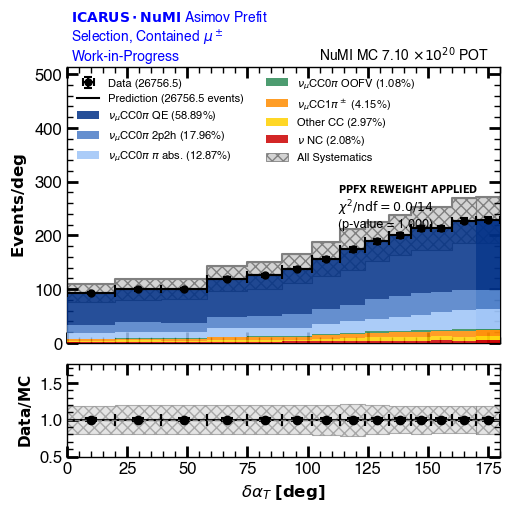

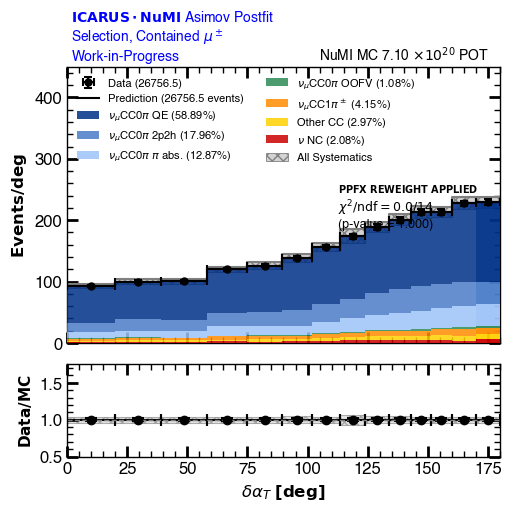

In [3]:
# Pre-fit plot
fig, axes, chi2_info = plot_gundam_stacked(
    postfit_file_path=PREFIT_FILE,
    fitterengine_file_path=ASIMOV_FILE,
    sample_name=SAMPLES['selection_contained'],
    variable_name='reco_dalphaT_deg',
    cov_bin_range=COV_RANGE['selection_contained'],
    fit_type='pre-fit',
    xlabel=r'$\delta\alpha_T$ $\mathbf{[deg]}$',
    ylabel=r'$\mathbf{Events / deg}$',
    title=r'$\bf{ICARUS \cdot NuMI}$ Asimov Prefit' + '\n' + r'Selection, Contained $\mu^\pm$' + '\n' + 'Work-in-Progress',
    save_dir=r'../Plots/dalphaT/Asimov_Containment_2D/Prefits', save_name='prefit_dalphaT_selection_contained',
    pot=POT,
)

# Post-fit plot
fig, axes, chi2_info = plot_gundam_stacked(
    postfit_file_path=POSTFIT_FILE,
    fitterengine_file_path=ASIMOV_FILE,
    sample_name=SAMPLES['selection_contained'],
    variable_name='reco_dalphaT_deg',
    cov_bin_range=COV_RANGE['selection_contained'],
    fit_type='post-fit',
    xlabel=r'$\delta\alpha_T$ $\mathbf{[deg]}$',
    ylabel=r'$\mathbf{Events / deg}$',
    title=r'$\bf{ICARUS \cdot NuMI}$ Asimov Postfit' + '\n' + r'Selection, Contained $\mu^\pm$' + '\n' + 'Work-in-Progress',
    pot=POT,
    save_dir=r'../Plots/dalphaT/Asimov_Containment_2D/Postfits', save_name='postfit_dalphaT_selection_contained'
)

## Selection - Exiting

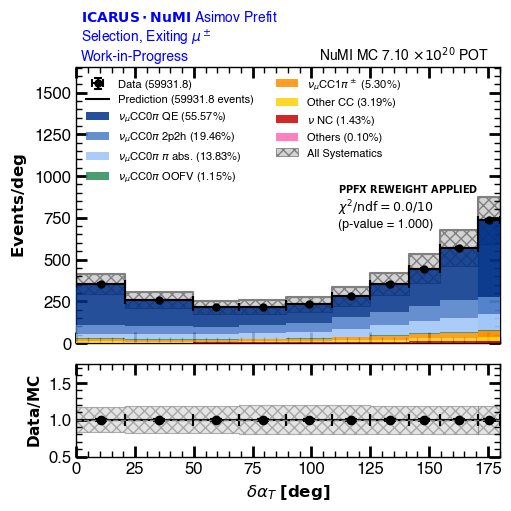

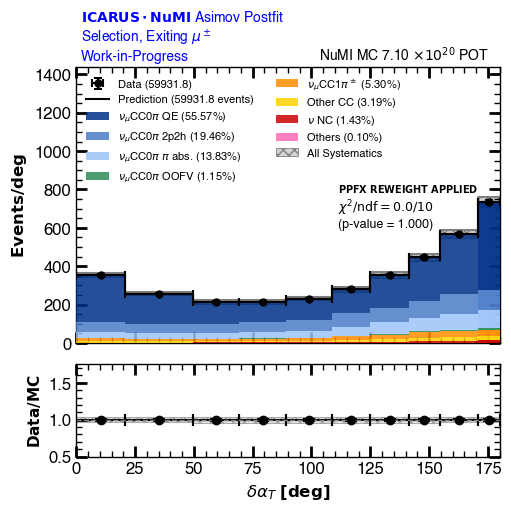

In [4]:
# Pre-fit plot
fig, axes, chi2_info = plot_gundam_stacked(
    postfit_file_path=PREFIT_FILE,
    fitterengine_file_path=ASIMOV_FILE,
    sample_name=SAMPLES['selection_exiting'],
    variable_name='reco_dalphaT_deg',
    cov_bin_range=COV_RANGE['selection_exiting'],
    fit_type='pre-fit',
    xlabel=r'$\delta\alpha_T$ $\mathbf{[deg]}$',
    ylabel=r'$\mathbf{Events / deg}$',
    title=r'$\bf{ICARUS \cdot NuMI}$ Asimov Prefit' + '\n' + r'Selection, Exiting $\mu^\pm$' + '\n' + 'Work-in-Progress',
    save_dir=r'../Plots/dalphaT/Asimov_Containment_2D/Prefits', save_name='prefit_dalphaT_selection_exiting',
    pot=POT,
)

# Post-fit plot
fig, axes, chi2_info = plot_gundam_stacked(
    postfit_file_path=POSTFIT_FILE,
    fitterengine_file_path=ASIMOV_FILE,
    sample_name=SAMPLES['selection_exiting'],
    variable_name='reco_dalphaT_deg',
    cov_bin_range=COV_RANGE['selection_exiting'],
    fit_type='post-fit',
    xlabel=r'$\delta\alpha_T$ $\mathbf{[deg]}$',
    ylabel=r'$\mathbf{Events / deg}$',
    title=r'$\bf{ICARUS \cdot NuMI}$ Asimov Postfit' + '\n' + r'Selection, Exiting $\mu^\pm$' + '\n' + 'Work-in-Progress',
    pot=POT,
    save_dir=r'../Plots/dalphaT/Asimov_Containment_2D/Postfits', save_name='postfit_dalphaT_selection_exiting'
)

## Sideband - Contained

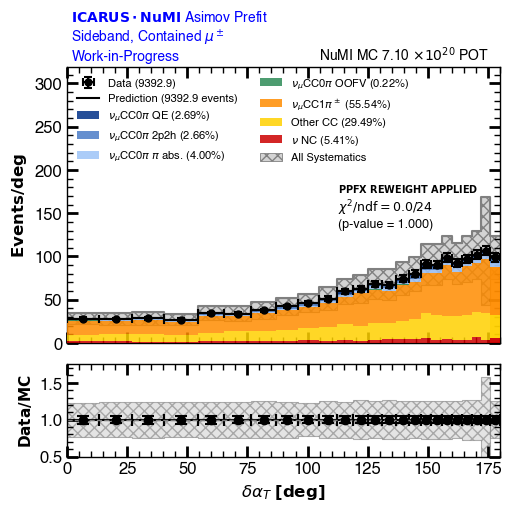

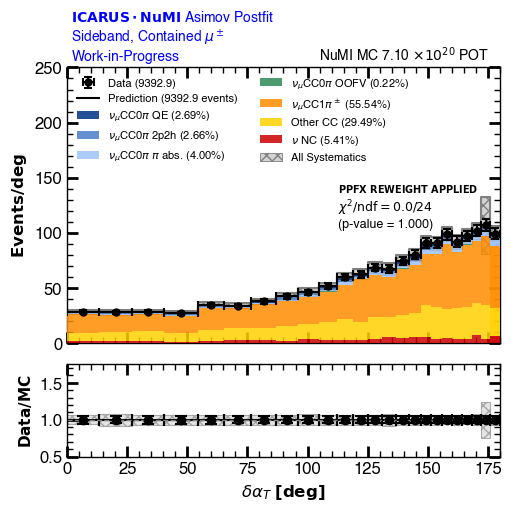

In [5]:
# Pre-fit plot
fig, axes, chi2_info = plot_gundam_stacked(
    postfit_file_path=PREFIT_FILE,
    fitterengine_file_path=ASIMOV_FILE,
    sample_name=SAMPLES['sideband_contained'],
    variable_name='reco_dalphaT_deg',
    cov_bin_range=COV_RANGE['sideband_contained'],
    fit_type='pre-fit',
    xlabel=r'$\delta\alpha_T$ $\mathbf{[deg]}$',
    ylabel=r'$\mathbf{Events / deg}$',
    title=r'$\bf{ICARUS \cdot NuMI}$ Asimov Prefit' + '\n' + r'Sideband, Contained $\mu^\pm$' + '\n' + 'Work-in-Progress',
    save_dir=r'../Plots/dalphaT/Asimov_Containment_2D/Prefits', save_name='prefit_dalphaT_sideband_contained',
    pot=POT,
)

# Post-fit plot
fig, axes, chi2_info = plot_gundam_stacked(
    postfit_file_path=POSTFIT_FILE,
    fitterengine_file_path=ASIMOV_FILE,
    sample_name=SAMPLES['sideband_contained'],
    variable_name='reco_dalphaT_deg',
    cov_bin_range=COV_RANGE['sideband_contained'],
    fit_type='post-fit',
    xlabel=r'$\delta\alpha_T$ $\mathbf{[deg]}$',
    ylabel=r'$\mathbf{Events / deg}$',
    title=r'$\bf{ICARUS \cdot NuMI}$ Asimov Postfit' + '\n' + r'Sideband, Contained $\mu^\pm$' + '\n' + 'Work-in-Progress',
    pot=POT,
    save_dir=r'../Plots/dalphaT/Asimov_Containment_2D/Postfits', save_name='postfit_dalphaT_sideband_contained'
)

## Sideband - Exiting

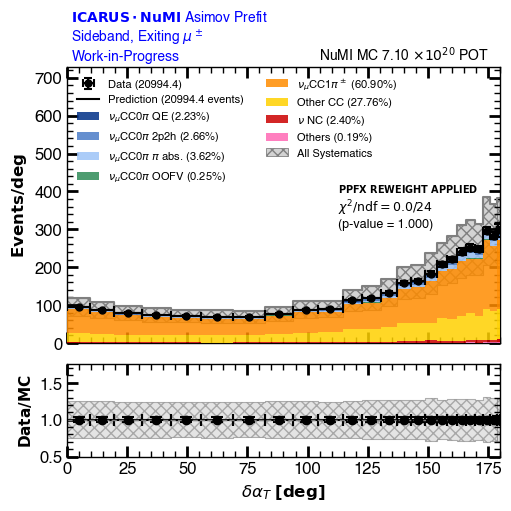

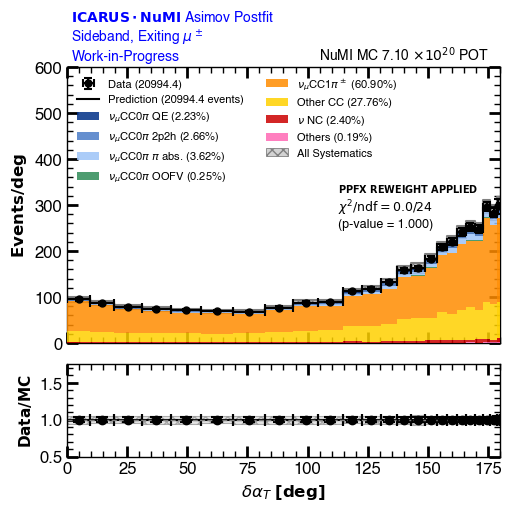

In [6]:
# Pre-fit plot
fig, axes, chi2_info = plot_gundam_stacked(
    postfit_file_path=PREFIT_FILE,
    fitterengine_file_path=ASIMOV_FILE,
    sample_name=SAMPLES['sideband_exiting'],
    variable_name='reco_dalphaT_deg',
    cov_bin_range=COV_RANGE['sideband_exiting'],
    fit_type='pre-fit',
    xlabel=r'$\delta\alpha_T$ $\mathbf{[deg]}$',
    ylabel=r'$\mathbf{Events / deg}$',
    title=r'$\bf{ICARUS \cdot NuMI}$ Asimov Prefit' + '\n' + r'Sideband, Exiting $\mu^\pm$' + '\n' + 'Work-in-Progress',
    save_dir=r'../Plots/dalphaT/Asimov_Containment_2D/Prefits', save_name='prefit_dalphaT_sideband_exiting',
    pot=POT,
)

# Post-fit plot
fig, axes, chi2_info = plot_gundam_stacked(
    postfit_file_path=POSTFIT_FILE,
    fitterengine_file_path=ASIMOV_FILE,
    sample_name=SAMPLES['sideband_exiting'],
    variable_name='reco_dalphaT_deg',
    cov_bin_range=COV_RANGE['sideband_exiting'],
    fit_type='post-fit',
    xlabel=r'$\delta\alpha_T$ $\mathbf{[deg]}$',
    ylabel=r'$\mathbf{Events / deg}$',
    title=r'$\bf{ICARUS \cdot NuMI}$ Asimov Postfit' + '\n' + r'Sideband, Exiting $\mu^\pm$' + '\n' + 'Work-in-Progress',
    pot=POT,
    save_dir=r'../Plots/dalphaT/Asimov_Containment_2D/Postfits', save_name='postfit_dalphaT_sideband_exiting'
)

## Cross-Section Extraction

Extracted from `asimov_XSec_dalphaT_containment_2D.root`. The 8 truth bins are reshaped to a $4 \times 2$ array ($\delta\alpha_T$ bin, $p_\mu$ bin) following the row order of the binning file. Units are cm$^2$/deg/Ar. The GUNDAM histogram and the manual calculation are both multiplied by $10^{40}$.

The first cell below reads the histogram and the second computes the manual cross-section from the true signal tree: $\sigma_{ik} = \sum w_{ik} \, / \, (N_{target} \cdot \Phi \cdot \Delta\delta\alpha_{T,i})$, with $w$ the `ppfx_cv_weight` of signal events (categories 0, 1, 2) in the bin. The third cell compares the two and decides whether GUNDAM divided by $\Delta p_\mu$ as well.

In [7]:
SCALE = 1e40
N_TARGETS = 4.721444e30
FLUX      = 5.1915e11

fx = uproot.open(XSEC_FILE)[XS_HIST]
xs_raw     = fx.values()
xs_err_raw = fx.errors()

# flat bin = N_PMU * i_dalphaT + i_pmu (row order of binning_true_dalphaT_deg_muonP.txt)
xs     = xs_raw.reshape(N_DA, N_PMU) * SCALE
xs_err = xs_err_raw.reshape(N_DA, N_PMU) * SCALE

print('GUNDAM extraction (x1e-40 cm2/deg/Ar as stored in the file)')
print(f'{"dalphaT [deg]":<16}{"pmu [GeV/c]":<18}{"xsec":>12}{"error":>12}{"rel. err":>10}')
for i in range(N_DA):
    for k in range(N_PMU):
        print(f'{DALPHA_EDGES[i]:>5.0f} - {DALPHA_EDGES[i+1]:<8.0f}{PMU_EDGES[k]:>5.1f} - {PMU_EDGES[k+1]:<9.1f}'
              f'{xs[i,k]:>12.4f}{xs_err[i,k]:>12.4f}{100*xs_err[i,k]/xs[i,k]:>9.1f}%')

GUNDAM extraction (x1e-40 cm2/deg/Ar as stored in the file)
dalphaT [deg]   pmu [GeV/c]               xsec       error  rel. err
    0 - 65        0.0 - 0.6            0.9783      0.1732     17.7%
    0 - 65        0.6 - 99999.0        0.0000      0.0000     14.9%
   65 - 114       0.0 - 0.6            1.2353      0.2203     17.8%
   65 - 114       0.6 - 99999.0        0.0000      0.0000     19.3%
  114 - 151       0.0 - 0.6            1.5851      0.2979     18.8%
  114 - 151       0.6 - 99999.0        0.0000      0.0000     18.1%
  151 - 180       0.0 - 0.6            1.6229      0.2948     18.2%
  151 - 180       0.6 - 99999.0        0.0000      0.0000     18.1%


In [8]:
SIGNAL_FILE = f"{SELECTION_DIR}/data/icarus_numi_numu_mc_onbeam_offbeam_syst_gundam.root"
tree = uproot.open(SIGNAL_FILE)["events/full/signal"]
arr = tree.arrays(["true_dalphaT_deg", "true_leading_muon_momentum", "category", "ppfx_cv_weight"], library="np")
is_sig = np.isin(arr["category"], [0, 1, 2])

# weighted signal events per (dalphaT, pmu) truth bin, pmu in GeV/c (same unit as the tree)
w_sum, _, _ = np.histogram2d(arr["true_dalphaT_deg"][is_sig], arr["true_leading_muon_momentum"][is_sig],
                             bins=[DALPHA_EDGES, PMU_EDGES], weights=arr["ppfx_cv_weight"][is_sig])
n_raw, _, _ = np.histogram2d(arr["true_dalphaT_deg"][is_sig], arr["true_leading_muon_momentum"][is_sig],
                             bins=[DALPHA_EDGES, PMU_EDGES])

da_width = np.diff(DALPHA_EDGES)[:, None]
manual_da_only = SCALE * w_sum / (N_TARGETS * FLUX * da_width)    # divided by the dalphaT width only

print('Signal events per truth bin (unweighted):')
print(n_raw.astype(int))
print('\nManual cross-section, divided by dalphaT width only [x1e-40 cm2/deg/Ar]:')
print(np.round(manual_da_only, 4))

Signal events per truth bin (unweighted):
[[10027 17599]
 [ 9545 17515]
 [ 9245 20340]
 [ 7416 20782]]

Manual cross-section, divided by dalphaT width only [x1e-40 cm2/deg/Ar]:
[[0.587  1.052 ]
 [0.7412 1.3885]
 [0.9511 2.135 ]
 [0.9738 2.7865]]


In [9]:
# Which normalisation did gundamCalcXsec use for the 2D bins?
# Option A: divided by dalphaT width only          -> GUNDAM / manual = 1
# Option B: divided by dalphaT width x pmu width   -> GUNDAM / manual = 1 / pmu width [GeV/c]
pmu_width = np.diff(PMU_EDGES)[None, :]
ratio = xs / manual_da_only

print('GUNDAM / manual (dalphaT-only normalisation):')
print(np.round(ratio, 4))
print('\nExpected if GUNDAM also divides by the pmu width, 1 / width:')
print(np.round(np.broadcast_to(1.0 / pmu_width, ratio.shape), 6))

score_A = np.sum(np.abs(np.log(ratio)))
score_B = np.sum(np.abs(np.log(ratio * pmu_width)))
DIVIDES_BY_PMU_WIDTH = bool(score_B < score_A)
print(f'\nsum|ln(ratio)|  option A (dalphaT only): {score_A:.3f}   option B (also pmu width): {score_B:.3f}')
print('->', 'GUNDAM divides by the pmu width too (option B)' if DIVIDES_BY_PMU_WIDTH
      else 'GUNDAM divides by the dalphaT width only (option A)')
print('Neither option should be trusted unless the ratio is close to 1 in every bin (flatten order and normalisation both check out).')

# manual prediction with the same normalisation as GUNDAM, used in the plots below
manual = manual_da_only / pmu_width if DIVIDES_BY_PMU_WIDTH else manual_da_only
ratio_check = xs / manual
print('\nFinal GUNDAM / manual per bin:')
print(np.round(ratio_check, 4))

GUNDAM / manual (dalphaT-only normalisation):
[[1.6667 0.    ]
 [1.6667 0.    ]
 [1.6667 0.    ]
 [1.6667 0.    ]]

Expected if GUNDAM also divides by the pmu width, 1 / width:
[[1.666667e+00 1.000000e-05]
 [1.666667e+00 1.000000e-05]
 [1.666667e+00 1.000000e-05]
 [1.666667e+00 1.000000e-05]]

sum|ln(ratio)|  option A (dalphaT only): 48.095   option B (also pmu width): 0.000
-> GUNDAM divides by the pmu width too (option B)
Neither option should be trusted unless the ratio is close to 1 in every bin (flatten order and normalisation both check out).

Final GUNDAM / manual per bin:
[[1. 1.]
 [1. 1.]
 [1. 1.]
 [1. 1.]]


/var/folders/hn/gg8vh0yd4j1382jb74b5wr780000gn/T/ipykernel_70703/1535510911.py:28: UserWarning: The figure layout has changed to tight
  fig.tight_layout()


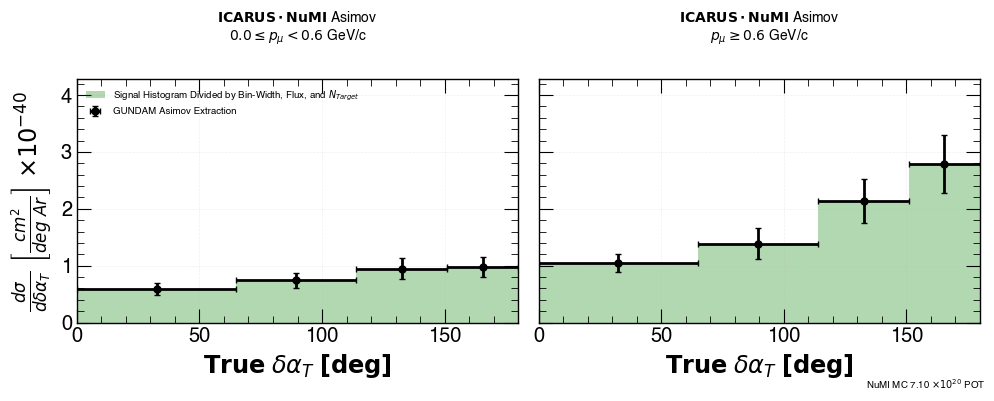

In [10]:
import matplotlib.pyplot as plt

# GUNDAM divided by the 2D bin volume. Multiply back by the pmu width so each panel shows
# dsigma/ddalphaT for events in that pmu range (the open-ended top bin would otherwise read ~1e-5).
back = np.diff(PMU_EDGES)[None, :] if DIVIDES_BY_PMU_WIDTH else np.ones((1, N_PMU))
xs_plot, xs_err_plot, manual_plot = xs * back, xs_err * back, manual * back

fig, axes = plt.subplots(1, N_PMU, figsize=(5 * N_PMU, 4), sharey=True)
ymax = 1.3 * np.max(np.maximum(manual_plot, xs_plot + xs_err_plot))   # common y-range for both pmu panels
centers = 0.5 * (np.array(DALPHA_EDGES[:-1]) + np.array(DALPHA_EDGES[1:]))
widths  = np.diff(DALPHA_EDGES)

for k, ax in enumerate(np.atleast_1d(axes)):
    ax.bar(centers, manual_plot[:, k], width=widths, color='green', alpha=0.30, edgecolor='green', linewidth=0,
           label=r'Signal Histogram Divided by Bin-Width, Flux, and $N_{Target}$')
    ax.errorbar(centers, xs_plot[:, k], xerr=widths / 2, yerr=xs_err_plot[:, k], fmt='o', color='black', markersize=5,
                capsize=2, label='GUNDAM Asimov Extraction')
    hi = PMU_EDGES[k + 1]
    pmu_label = rf'${PMU_EDGES[k]:.1f} \leq p_\mu < {hi:.1f}$ GeV/c' if hi < 1e3 else rf'$p_\mu \geq {PMU_EDGES[k]:.1f}$ GeV/c'
    ax.set_title(r'$\bf{ICARUS \cdot NuMI}$ Asimov' + '\n' + pmu_label, fontsize=10)
    ax.set_xlabel(r'$\mathbf{True}$ $\delta\alpha_T$ $\mathbf{[deg]}$')
    ax.set_xlim(DALPHA_EDGES[0], DALPHA_EDGES[-1])
    ax.set_ylim(0, ymax)
    ax.grid(alpha=0.2)
np.atleast_1d(axes)[0].set_ylabel(r'$\frac{d\sigma}{d\delta\alpha_T}$ $\left[\frac{cm^2}{deg\ Ar}\right]$ $\times 10^{-40}$')
np.atleast_1d(axes)[0].legend(fontsize=7, loc='upper left', framealpha=0.8)
fig.text(0.99, 0.01, POT, ha='right', va='bottom', fontsize=7)
fig.tight_layout()
save_fig(fig, PLOT_DIR + '/XSection', 'dalphaT_muonP_XS')
plt.close(fig)   # avoid the inline backend drawing the figure a second time
display(fig)

### GENIE (NUISANCE flat tree) comparison

An Asimov fit returns the MC prediction, so the extraction should agree with the generator. The GENIE AR23_20i prediction is built from the NUISANCE flat trees with the same recipe as `overlay_genie_nuisance_xsec` in the 1D notebook: signal flag `ICARUS_1muNp0pi_IsSignal`, weight `InputWeight` $\times$ `fScaleFactor`, divided by the number of files and the $\delta\alpha_T$ width, times 40 nucleons, and the $\nu_\mu$ and $\bar\nu_\mu$ samples combined with their flux integrals as weights.

The flat tree has no signal muon momentum branch. The muon momentum is computed from the lepton branches, $p_\mu = \sqrt{E_{\rm lep}^2 - m_{\rm lep}^2}$, which are stored in MeV, so it is divided by 1000 to get GeV/c.

Two $\chi^2$ values are printed. The first uses the diagonal errors only, as in the 1D overlay. The second also uses the post-fit covariance of the template parameters, scaled to the cross-section as $C_{ij} = \sigma_i \sigma_j \, \mathrm{Cov}(c_i, c_j)$. The template parameters are strongly correlated, so the second is the more demanding test.

In [11]:
import glob
from scipy.stats import chi2 as chi2_dist

GENIE_NU    = f"{GUNDAM_DIR}/data/Generators/GENIE/fhc_Nu14"
GENIE_NUBAR = f"{GUNDAM_DIR}/data/Generators/GENIE/fhc_Nu-14"
N_NUCLEONS  = 40

def genie_2d(file_dir):
    files = sorted(f for f in glob.glob(f"{file_dir}/output_GENIE_*.nuisflat.root") if os.path.getsize(f) > 0)
    h, flux = np.zeros((N_DA, N_PMU)), None
    for fpath in files:
        with uproot.open(fpath) as r:
            a = r["FlatTree_VARS"].arrays(["ICARUS_1muNp0pi_IsSignal", "ICARUS_1muNp0pi_deltaalphaT",
                                           "ELep", "MLep", "InputWeight", "fScaleFactor"], library="np")
            if flux is None:
                fv, fb = r["FlatTree_FLUX"].to_numpy()
                flux = np.sum(fv * np.diff(fb)) * 1e-4          # /m^2 -> /cm^2
        m = a["ICARUS_1muNp0pi_IsSignal"] == True
        w = (a["InputWeight"] * a["fScaleFactor"])[m]
        pmu = np.sqrt(np.maximum(a["ELep"][m] ** 2 - a["MLep"][m] ** 2, 0.0)) / 1000.0   # MeV -> GeV/c
        h += np.histogram2d(a["ICARUS_1muNp0pi_deltaalphaT"][m], pmu, bins=[DALPHA_EDGES, PMU_EDGES], weights=w)[0]
    return h / np.diff(DALPHA_EDGES)[:, None] / len(files) * N_NUCLEONS, flux

h_nu, flux_nu       = genie_2d(GENIE_NU)
h_nubar, flux_nubar = genie_2d(GENIE_NUBAR)
genie = (h_nu * flux_nu + h_nubar * flux_nubar) / (flux_nu + flux_nubar) * SCALE   # dsigma/ddalphaT per pmu range, x1e-40

# Compare in the same units as the plotted extraction (dsigma/ddalphaT per pmu range)
x_ext, e_ext, g = xs_plot.reshape(-1), xs_err_plot.reshape(-1), genie.reshape(-1)
res = x_ext - g

chi2_diag = np.sum((res / e_ext) ** 2)
ndof = len(x_ext)
p_diag = 1.0 - chi2_dist.cdf(chi2_diag, ndof)

cov_t = uproot.open(ASIMOV_FILE)[f"FitterEngine/postFit/Hesse/errors/{TEMPLATE_NAME};1/matrices/Covariance_TH2D;1"].values()
cov_xs = np.outer(x_ext, x_ext) * cov_t
chi2_full = res @ np.linalg.solve(cov_xs, res)
p_full = 1.0 - chi2_dist.cdf(chi2_full, ndof)

print(f'{"dalphaT [deg]":<16}{"pmu [GeV/c]":<16}{"GUNDAM":>9}{"error":>9}{"GENIE":>9}{"GENIE/GUNDAM":>14}{"pull":>8}')
for n in range(ndof):
    i, k = divmod(n, N_PMU)
    hi = PMU_EDGES[k + 1]
    pm = f'{PMU_EDGES[k]:.1f} - {hi:.1f}' if hi < 1e3 else f'>= {PMU_EDGES[k]:.1f}'
    print(f'{DALPHA_EDGES[i]:>5.0f} - {DALPHA_EDGES[i+1]:<8.0f}{pm:<16}{x_ext[n]:>9.4f}{e_ext[n]:>9.4f}{g[n]:>9.4f}{g[n]/x_ext[n]:>14.3f}{res[n]/e_ext[n]:>8.2f}')
print(f'\nchi2/ndof, diagonal errors (same convention as the 1D overlay): {chi2_diag:.2f} / {ndof} = {chi2_diag/ndof:.3f}   p-value = {p_diag:.3f}')
print(f'chi2/ndof, template-parameter covariance:                       {chi2_full:.2f} / {ndof} = {chi2_full/ndof:.3f}   p-value = {p_full:.3f}')

dalphaT [deg]   pmu [GeV/c]        GUNDAM    error    GENIE  GENIE/GUNDAM    pull
    0 - 65      0.0 - 0.6          0.5870   0.1039   0.5888         1.003   -0.02
    0 - 65      >= 0.6             1.0520   0.1563   0.9664         0.919    0.55
   65 - 114     0.0 - 0.6          0.7412   0.1322   0.7721         1.042   -0.23
   65 - 114     >= 0.6             1.3885   0.2680   1.3834         0.996    0.02
  114 - 151     0.0 - 0.6          0.9511   0.1787   0.9969         1.048   -0.26
  114 - 151     >= 0.6             2.1350   0.3857   2.3301         1.091   -0.51
  151 - 180     0.0 - 0.6          0.9738   0.1769   1.0171         1.045   -0.25
  151 - 180     >= 0.6             2.7865   0.5035   2.9473         1.058   -0.32

chi2/ndof, diagonal errors (same convention as the 1D overlay): 0.84 / 8 = 0.105   p-value = 0.999
chi2/ndof, template-parameter covariance:                       3.99 / 8 = 0.498   p-value = 0.858


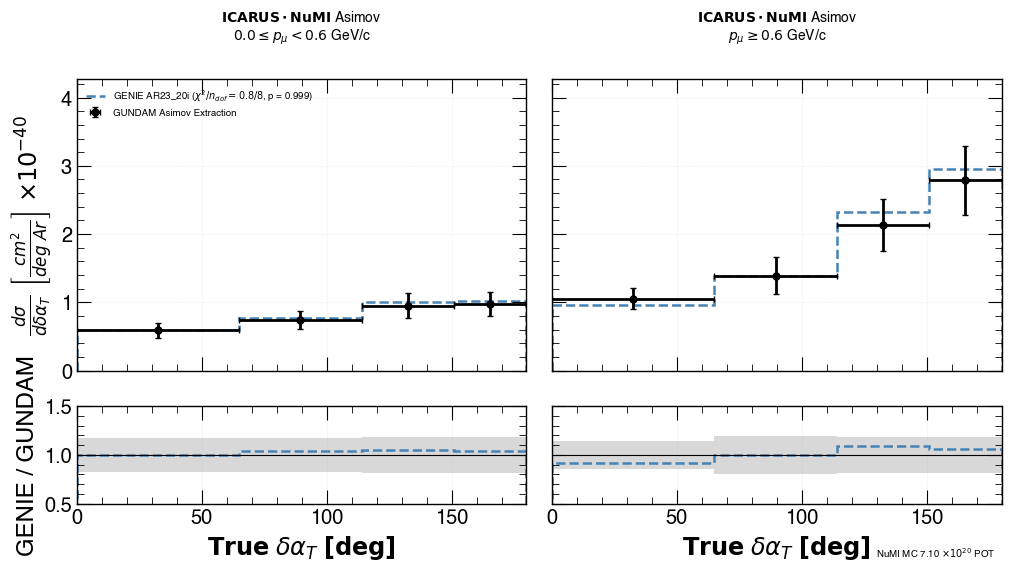

In [12]:
fig = plt.figure(figsize=(5 * N_PMU, 5.6))
gs = fig.add_gridspec(2, N_PMU, height_ratios=[3, 1], hspace=0.06, wspace=0.04)
ymax_g = 1.3 * np.max(np.maximum(np.maximum(manual_plot, genie), xs_plot + xs_err_plot))
for k in range(N_PMU):
    ax  = fig.add_subplot(gs[0, k])
    axr = fig.add_subplot(gs[1, k], sharex=ax)
    ax.stairs(genie[:, k], DALPHA_EDGES, color='steelblue', linestyle='--', linewidth=1.8,
              label=rf'GENIE AR23_20i ($\chi^2/n_{{dof}} = {chi2_diag:.1f}/{ndof}$, p = {p_diag:.3f})' if k == 0 else None)
    ax.errorbar(centers, xs_plot[:, k], xerr=widths / 2, yerr=xs_err_plot[:, k], fmt='o', color='black',
                markersize=5, capsize=2, label='GUNDAM Asimov Extraction' if k == 0 else None)
    hi = PMU_EDGES[k + 1]
    pmu_label = rf'${PMU_EDGES[k]:.1f} \leq p_\mu < {hi:.1f}$ GeV/c' if hi < 1e3 else rf'$p_\mu \geq {PMU_EDGES[k]:.1f}$ GeV/c'
    ax.set_title(r'$\bf{ICARUS \cdot NuMI}$ Asimov' + '\n' + pmu_label, fontsize=10)
    ax.set_xlim(DALPHA_EDGES[0], DALPHA_EDGES[-1]); ax.set_ylim(0, ymax_g); ax.grid(alpha=0.2)
    plt.setp(ax.get_xticklabels(), visible=False)
    if k > 0: plt.setp(ax.get_yticklabels(), visible=False)
    # ratio panel: GENIE / GUNDAM, band = relative error of the extraction
    ratio = genie[:, k] / xs_plot[:, k]
    rel = xs_err_plot[:, k] / xs_plot[:, k]
    axr.bar(centers, 2 * rel, bottom=1 - rel, width=widths, color='gray', alpha=0.3, linewidth=0)
    axr.stairs(ratio, DALPHA_EDGES, color='steelblue', linestyle='--', linewidth=1.8)
    axr.axhline(1, color='black', linewidth=0.8)
    axr.set_ylim(0.5, 1.5); axr.grid(alpha=0.2)
    axr.set_xlabel(r'$\mathbf{True}$ $\delta\alpha_T$ $\mathbf{[deg]}$')
    if k > 0: plt.setp(axr.get_yticklabels(), visible=False)
fig.axes[0].set_ylabel(r'$\frac{d\sigma}{d\delta\alpha_T}$ $\left[\frac{cm^2}{deg\ Ar}\right]$ $\times 10^{-40}$')
fig.axes[1].set_ylabel('GENIE / GUNDAM')
fig.axes[0].legend(fontsize=7, loc='upper left', framealpha=0.8)
fig.text(0.99, 0.01, POT, ha='right', va='bottom', fontsize=7)
save_fig(fig, PLOT_DIR + '/XSection', 'dalphaT_muonP_XS_wGENIE')
plt.close(fig)   # avoid the inline backend drawing the figure a second time
display(fig)

### Integrated over $p_\mu$ vs the 1D extraction

Summing the two $p_\mu$ slices of each $\delta\alpha_T$ bin should reproduce the 1D cross-section from the 1D Asimov fit. In an Asimov fit both extractions return the MC prediction, so they must agree within numerical precision. A mismatch points to a normalisation or bin-order problem, not to physics. Only central values are compared: the error of the sum needs the covariance between the two template parameters of each bin, which is not computed here.

dalphaT [deg]      1D GUNDAM   2D summed    2D/1D   manual sum
    0 - 65            1.6390      1.6390    1.000       1.6390
   65 - 114           2.1297      2.1297    1.000       2.1297
  114 - 151           3.0860      3.0860    1.000       3.0860
  151 - 180           3.7603      3.7603    1.000       3.7603


/var/folders/hn/gg8vh0yd4j1382jb74b5wr780000gn/T/ipykernel_70703/2364501887.py:20: UserWarning: The figure layout has changed to tight
  fig.tight_layout()


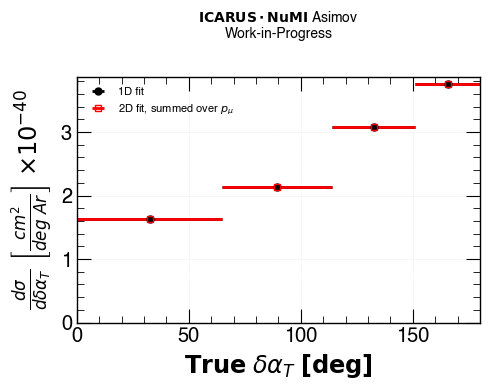

In [13]:
h1d = uproot.open(XSEC_FILE_1D)[XS_HIST_1D]
xs_1d = h1d.values() * SCALE

# sum over pmu: slices are already per-dalphaT-width; multiply back by pmu width if GUNDAM divided by it
weights_pmu = np.diff(PMU_EDGES)[None, :] if DIVIDES_BY_PMU_WIDTH else np.ones((1, N_PMU))
xs_sum = np.sum(xs * weights_pmu, axis=1)
manual_sum = np.sum(manual * weights_pmu, axis=1)

print(f'{"dalphaT [deg]":<16}{"1D GUNDAM":>12}{"2D summed":>12}{"2D/1D":>9}{"manual sum":>13}')
for i in range(N_DA):
    print(f'{DALPHA_EDGES[i]:>5.0f} - {DALPHA_EDGES[i+1]:<8.0f}{xs_1d[i]:>12.4f}{xs_sum[i]:>12.4f}{xs_sum[i]/xs_1d[i]:>9.3f}{manual_sum[i]:>13.4f}')

fig, ax = plt.subplots(figsize=(5, 4))
ax.errorbar(centers, xs_1d, xerr=widths / 2, fmt='o', color='black', markersize=5, label='1D fit')
ax.errorbar(centers, xs_sum, xerr=widths / 2, fmt='s', color='red', markersize=5, mfc='none', label=r'2D fit, summed over $p_\mu$')
ax.set_xlabel(r'$\mathbf{True}$ $\delta\alpha_T$ $\mathbf{[deg]}$')
ax.set_ylabel(r'$\frac{d\sigma}{d\delta\alpha_T}$ $\left[\frac{cm^2}{deg\ Ar}\right]$ $\times 10^{-40}$')
ax.set_title(r'$\bf{ICARUS \cdot NuMI}$ Asimov' + '\n' + 'Work-in-Progress', fontsize=10)
ax.set_xlim(DALPHA_EDGES[0], DALPHA_EDGES[-1]); ax.set_ylim(bottom=0); ax.grid(alpha=0.2); ax.legend(fontsize=8)
fig.tight_layout()
save_fig(fig, PLOT_DIR + '/XSection', 'dalphaT_muonP_XS_integrated_vs_1D')
plt.close(fig)   # avoid the inline backend drawing the figure a second time
display(fig)

## Template Parameter Post-fit Values

One set of 8 template parameters shared by the four samples. The x axis is the flat truth-bin index, $2 \cdot i_{\delta\alpha_T} + i_{p_\mu}$ (even index: $p_\mu < 0.6$ GeV/c, odd index: $p_\mu \geq 0.6$ GeV/c). In an Asimov fit every parameter must sit at 1. The error bars are the quantity to compare with the stat-only estimate of 15-25%.

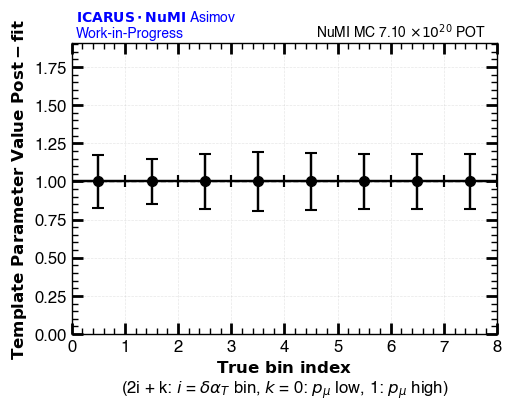

In [14]:
fig_template, ax_template, dummy, dummy2 = plot_scatter(
        filename=ASIMOV_FILE,
        is_cross_section=False,
        hist_path=f"FitterEngine/postFit/Hesse/errors/{TEMPLATE_NAME}/values/postFitErrors_TH1D;1",
        xlabel=r'$\mathbf{True\ bin\ index}$' + '\n' + r'(2i + k: $i$ = $\delta\alpha_T$ bin, $k$ = 0: $p_\mu$ low, 1: $p_\mu$ high)',
        ylabel='$\mathbf{Template\ Parameter\ Value\ Post-fit}$',
        bin_edges_labels=list(range(N_DA * N_PMU + 1)),
        remove_last_bin=False,
        is_y_errors=True,
        title_line1=r'$\bf{ICARUS \cdot NuMI}$ Asimov' + '\n' + 'Work-in-Progress',
        label=None,
        hline_nuisance=True,
        pot=POT
)
save_fig(fig_template, PLOT_DIR + '/TemplateParameters', 'dalphaT_muonP')

flat bin  dalphaT [deg]   pmu [GeV/c]        value    error
0             0 - 65        0.0 - 0.6         1.000    0.175
1             0 - 65        0.6 - 99999.0     1.000    0.147
2            65 - 114       0.0 - 0.6         1.000    0.177
3            65 - 114       0.6 - 99999.0     1.000    0.191
4           114 - 151       0.0 - 0.6         1.000    0.185
5           114 - 151       0.6 - 99999.0     1.000    0.178
6           151 - 180       0.0 - 0.6         1.000    0.181
7           151 - 180       0.6 - 99999.0     1.000    0.178
Full matrix size: 8×8


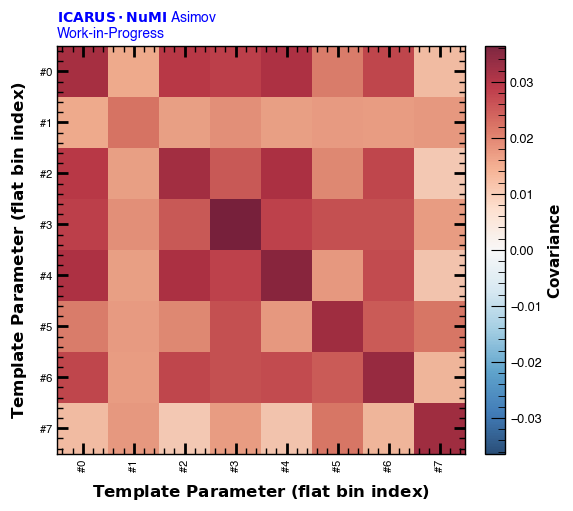

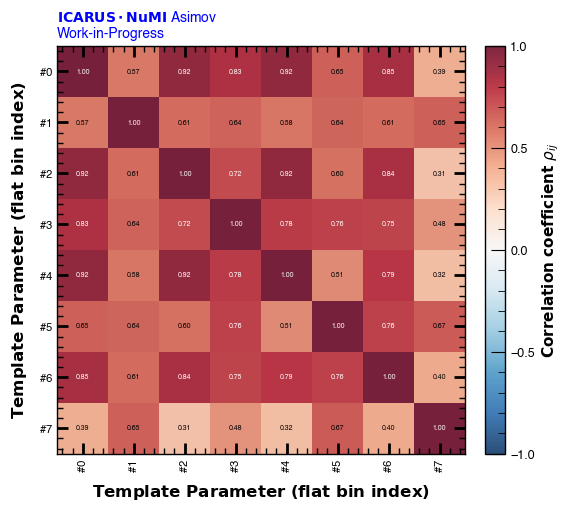

In [15]:
# Post-fit uncertainty of each template parameter and the correlation between them
BASE = "FitterEngine/postFit/Hesse/errors"
tp_hist = uproot.open(ASIMOV_FILE)[f"{BASE}/{TEMPLATE_NAME}/values/postFitErrors_TH1D;1"]
print(f'{"flat bin":<10}{"dalphaT [deg]":<16}{"pmu [GeV/c]":<16}{"value":>8}{"error":>9}')
for n, (v, e) in enumerate(zip(tp_hist.values(), tp_hist.errors())):
    i, k = divmod(n, N_PMU)
    print(f'{n:<10}{DALPHA_EDGES[i]:>5.0f} - {DALPHA_EDGES[i+1]:<8.0f}{PMU_EDGES[k]:>5.1f} - {PMU_EDGES[k+1]:<9.1f}{v:>8.3f}{e:>9.3f}')

(fig_cov, ax_cov), (fig_corr, ax_corr) = plot_both_matrices(
    ASIMOV_FILE,
    figsize=(6, 5),
    label_name=r"$\mathbf{Template\ Parameter\ (flat\ bin\ index)}$",
    cov_path  = f"{BASE}/{TEMPLATE_NAME};1/matrices/Covariance_TH2D;1",
    corr_path = f"{BASE}/{TEMPLATE_NAME};1/matrices/Correlation_TH2D;1",
    title_line1=r'$\bf{ICARUS \cdot NuMI}$ Asimov' + '\n' + 'Work-in-Progress',
    annotate=True,
)
save_fig(fig_cov, PLOT_DIR + '/Postfits', 'template_param_covariance')
save_fig(fig_corr, PLOT_DIR + '/Postfits', 'template_param_correlation')

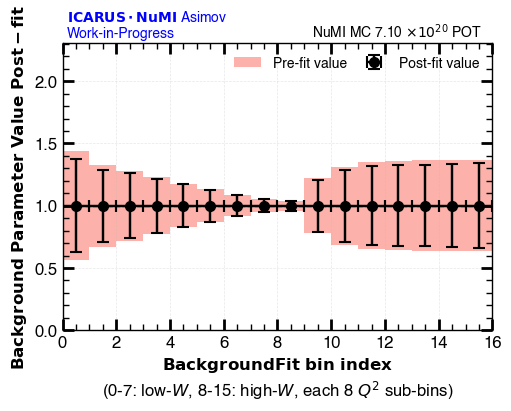

In [16]:
fig_bkg_template, ax_bkg_template, dummy, dummy2 = plot_scatter(
        filename=ASIMOV_FILE,
        is_cross_section=False,
        hist_path="FitterEngine/postFit/Hesse/errors/BackgroundFit true_generator_w binbybin/values/postFitErrors_TH1D;1",
        xlabel=r'$\mathbf{BackgroundFit\ bin\ index}$' + '\n' + r'(0-7: low-$W$, 8-15: high-$W$, each 8 $Q^2$ sub-bins)',
        ylabel=r'$\mathbf{Background\ Parameter\ Value\ Post-fit}$',
        bin_edges_labels=list(range(17)),   # 17 edges -> 16 unit-width bins, matches the 16 real bins exactly
        remove_last_bin=False,               # there is no overflow bin in this scheme -- don't drop bin 15
        is_y_errors=True,
        title_line1=r'$\bf{ICARUS \cdot NuMI}$ Asimov' + '\n' + 'Work-in-Progress',
        hline_nuisance=True,
        pot=POT,
        show_prior=True,
)
save_fig(fig_bkg_template, r'../Plots/dalphaT/Asimov_Containment_2D/BackgroundFitParameters', 'dalphaT')

## Nuisance Parameter Constraints

Pre-fit/post-fit constraint plots for the interaction-model, flux, and detector systematics. These dial sets do not depend on the observable or on the reco-level split (`applyOnDataSets` is keyed by dataset name, not fitSample name), so this is one set of plots for the whole joint fit. The G4 sets are the dalphaT versions, whose covariances are binned in reco $\delta\alpha_T$ (14 contained parameters, 10 exiting).

Number of parameters: 52


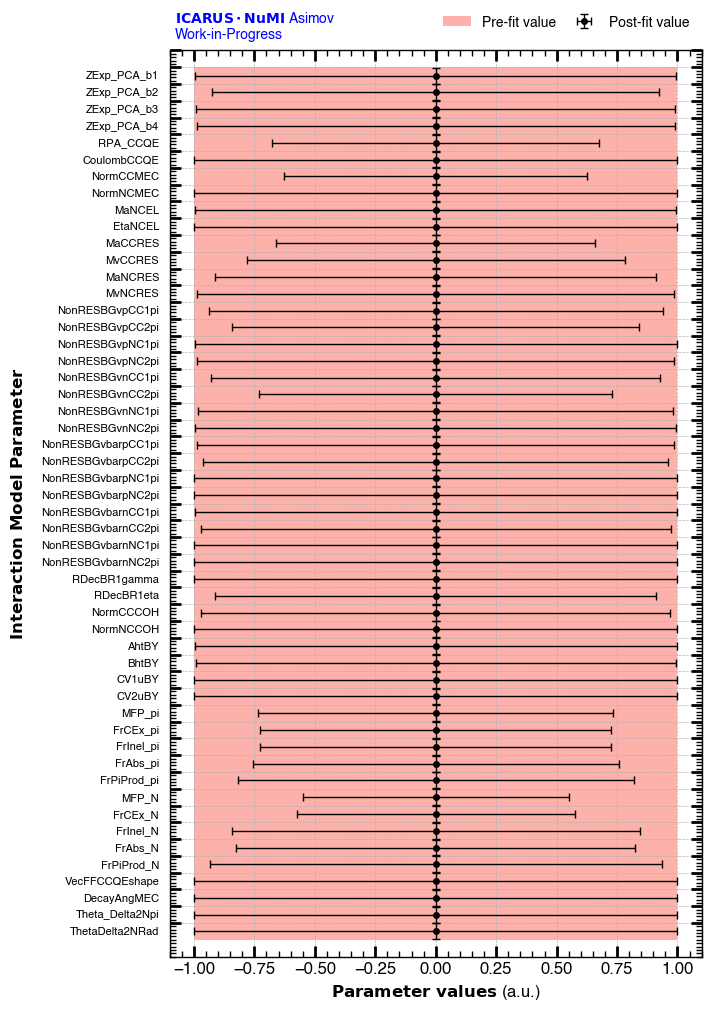

In [17]:
fig, ax = plot_fit_constraints(
    filename=ASIMOV_FILE,
    figsize=(7, 10),
    y_label=r'$\mathbf{Interaction\ Model\ Parameter}$',
    directory_path="FitterEngine/postFit/Hesse/errors/Cross section Systematics/values",
    title_line1=r'$\bf{ICARUS \cdot NuMI}$ Asimov' + '\n' + 'Work-in-Progress'
)
save_fig(fig, r'../Plots/dalphaT/Asimov_Containment_2D/NuisanceParameters', 'dalphaT_InteractionModel')

Number of parameters: 27


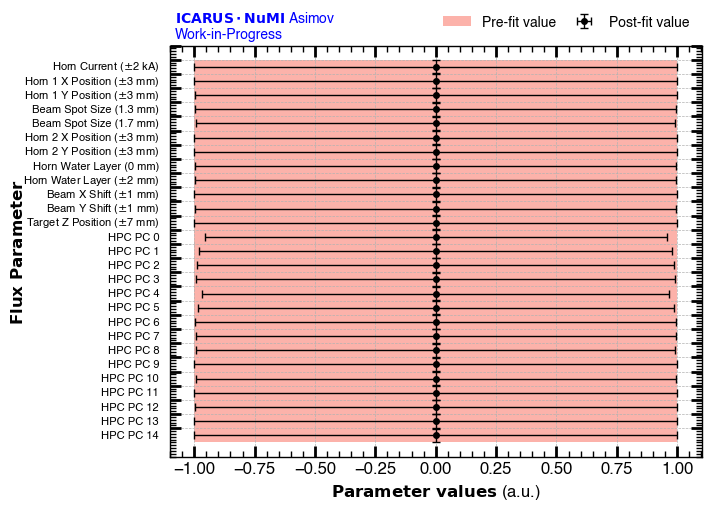

In [18]:
fig, ax = plot_fit_constraints(
    filename=ASIMOV_FILE,
    figsize=(7, 5),
    y_label=r'$\mathbf{Flux\ Parameter}$',
    directory_path="FitterEngine/postFit/Hesse/errors/Multisigma Flux Systematics/values",
    title_line1=r'$\bf{ICARUS \cdot NuMI}$ Asimov' + '\n' + 'Work-in-Progress'
)
save_fig(fig, r'../Plots/dalphaT/Asimov_Containment_2D/NuisanceParameters', 'dalphaT_Flux')

Number of parameters: 9


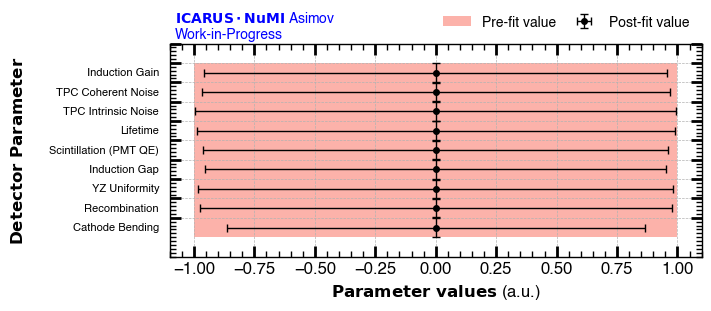

In [19]:
fig, ax = plot_fit_constraints(
    filename=ASIMOV_FILE,
    figsize=(7, 3),
    y_label=r'$\mathbf{Detector\ Parameter}$',
    directory_path="FitterEngine/postFit/Hesse/errors/Detector Systematics/values",
    title_line1=r'$\bf{ICARUS \cdot NuMI}$ Asimov' + '\n' + 'Work-in-Progress'
)
save_fig(fig, r'../Plots/dalphaT/Asimov_Containment_2D/NuisanceParameters', 'dalphaT_Detector')

Number of parameters: 14


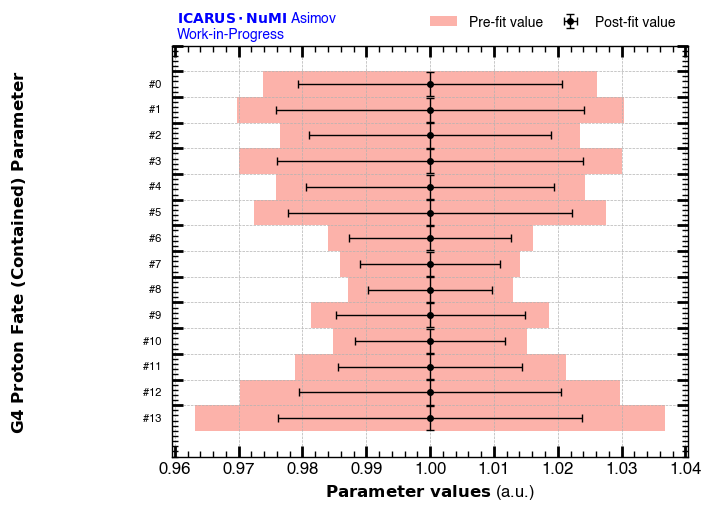

In [20]:
fig, ax = plot_fit_constraints(
    filename=ASIMOV_FILE,
    figsize=(7, 5),
    y_label=r'$\mathbf{G4\ Proton\ Fate\ (Contained)\ Parameter}$',
    directory_path="FitterEngine/postFit/Hesse/errors/G4 Proton Fate (dalphaT, contained)/values",
    title_line1=r'$\bf{ICARUS \cdot NuMI}$ Asimov' + '\n' + 'Work-in-Progress'
)
save_fig(fig, r'../Plots/dalphaT/Asimov_Containment_2D/NuisanceParameters', 'dalphaT_G4_Proton_Contained')

Number of parameters: 10


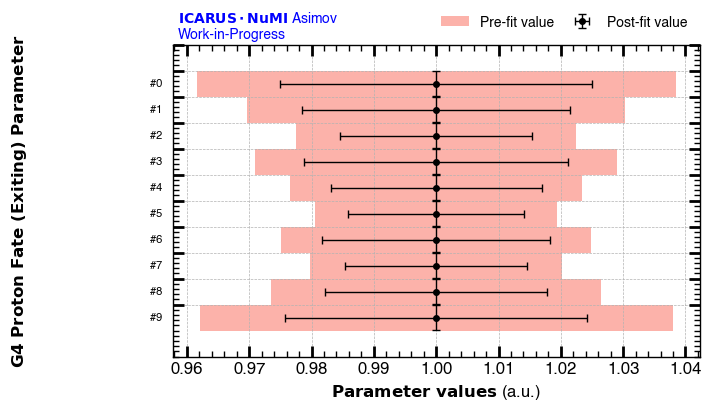

In [21]:
fig, ax = plot_fit_constraints(
    filename=ASIMOV_FILE,
    figsize=(7, 4),
    y_label=r'$\mathbf{G4\ Proton\ Fate\ (Exiting)\ Parameter}$',
    directory_path="FitterEngine/postFit/Hesse/errors/G4 Proton Fate (dalphaT, exiting)/values",
    title_line1=r'$\bf{ICARUS \cdot NuMI}$ Asimov' + '\n' + 'Work-in-Progress'
)
save_fig(fig, r'../Plots/dalphaT/Asimov_Containment_2D/NuisanceParameters', 'dalphaT_G4_Proton_Exiting')

Number of parameters: 14


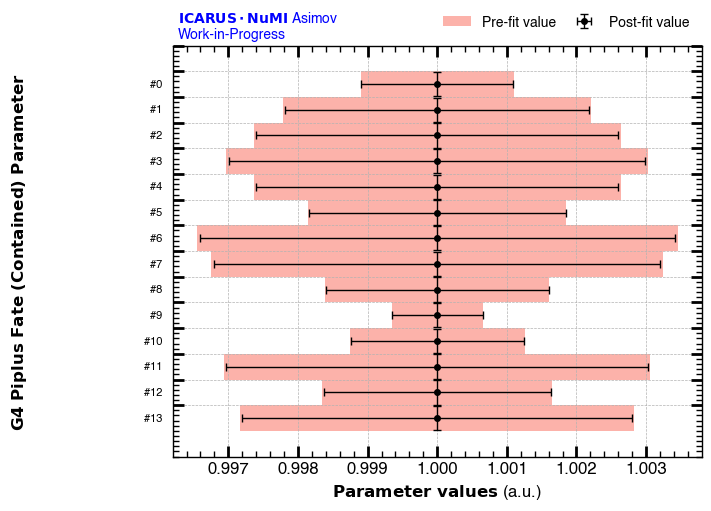

In [22]:
fig, ax = plot_fit_constraints(
    filename=ASIMOV_FILE,
    figsize=(7, 5),
    y_label=r'$\mathbf{G4\ Piplus\ Fate\ (Contained)\ Parameter}$',
    directory_path="FitterEngine/postFit/Hesse/errors/G4 Piplus Fate (dalphaT, contained)/values",
    title_line1=r'$\bf{ICARUS \cdot NuMI}$ Asimov' + '\n' + 'Work-in-Progress'
)
save_fig(fig, r'../Plots/dalphaT/Asimov_Containment_2D/NuisanceParameters', 'dalphaT_G4_Piplus_Contained')

Number of parameters: 10


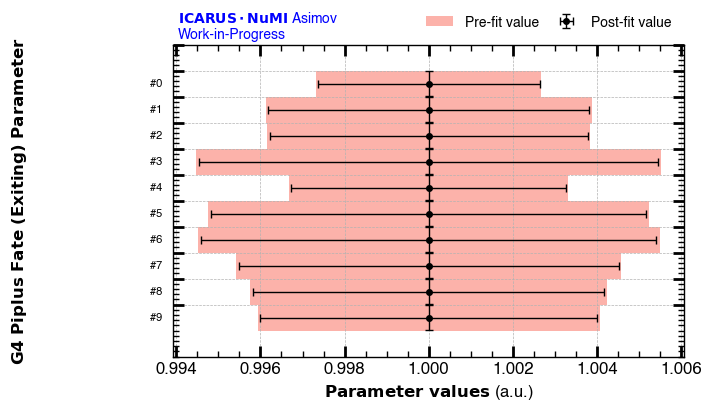

In [23]:
fig, ax = plot_fit_constraints(
    filename=ASIMOV_FILE,
    figsize=(7, 4),
    y_label=r'$\mathbf{G4\ Piplus\ Fate\ (Exiting)\ Parameter}$',
    directory_path="FitterEngine/postFit/Hesse/errors/G4 Piplus Fate (dalphaT, exiting)/values",
    title_line1=r'$\bf{ICARUS \cdot NuMI}$ Asimov' + '\n' + 'Work-in-Progress'
)
save_fig(fig, r'../Plots/dalphaT/Asimov_Containment_2D/NuisanceParameters', 'dalphaT_G4_Piplus_Exiting')

Number of parameters: 14


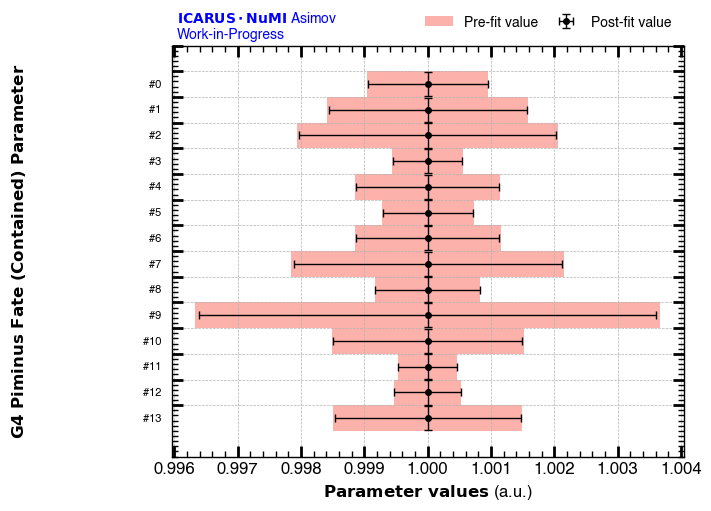

In [24]:
fig, ax = plot_fit_constraints(
    filename=ASIMOV_FILE,
    figsize=(7, 5),
    y_label=r'$\mathbf{G4\ Piminus\ Fate\ (Contained)\ Parameter}$',
    directory_path="FitterEngine/postFit/Hesse/errors/G4 Piminus Fate (dalphaT, contained)/values",
    title_line1=r'$\bf{ICARUS \cdot NuMI}$ Asimov' + '\n' + 'Work-in-Progress'
)
save_fig(fig, r'../Plots/dalphaT/Asimov_Containment_2D/NuisanceParameters', 'dalphaT_G4_Piminus_Contained')

Number of parameters: 10


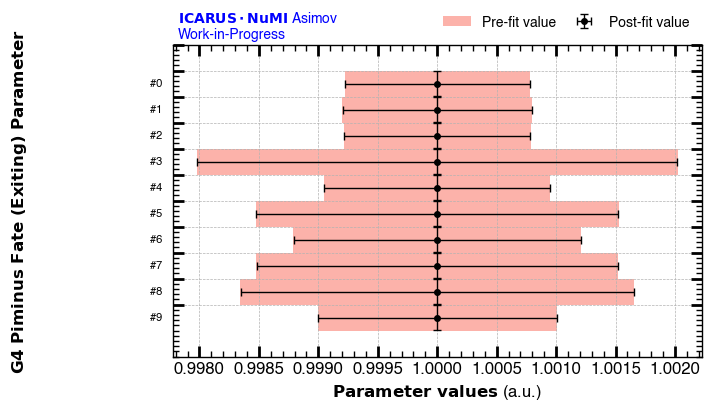

In [25]:
fig, ax = plot_fit_constraints(
    filename=ASIMOV_FILE,
    figsize=(7, 4),
    y_label=r'$\mathbf{G4\ Piminus\ Fate\ (Exiting)\ Parameter}$',
    directory_path="FitterEngine/postFit/Hesse/errors/G4 Piminus Fate (dalphaT, exiting)/values",
    title_line1=r'$\bf{ICARUS \cdot NuMI}$ Asimov' + '\n' + 'Work-in-Progress'
)
save_fig(fig, r'../Plots/dalphaT/Asimov_Containment_2D/NuisanceParameters', 'dalphaT_G4_Piminus_Exiting')

## Covariance / Correlation Matrices

Per-systematic-block matrices (interaction model, flux, detector, G4) -- these are among the nuisance parameters themselves, not among reco bins, so `bin_range` is left at its default (full block). Not to be confused with the reco-bin covariance used inside `plot_gundam_stacked`'s chi2 calculation, which is a different matrix (`toyGen/matrices/covarianceMatrix_TH2D`).

Full matrix size: 52×52


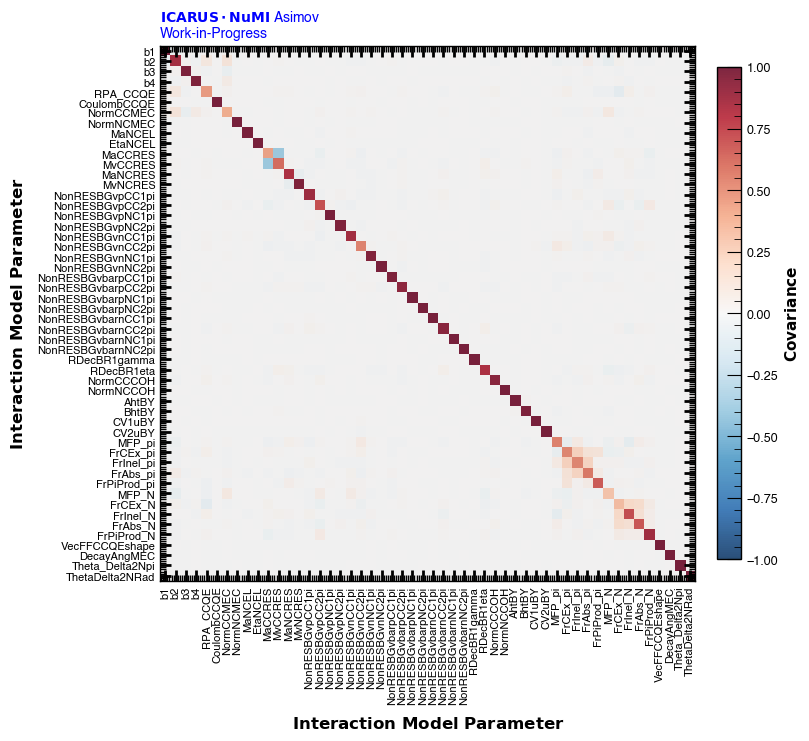

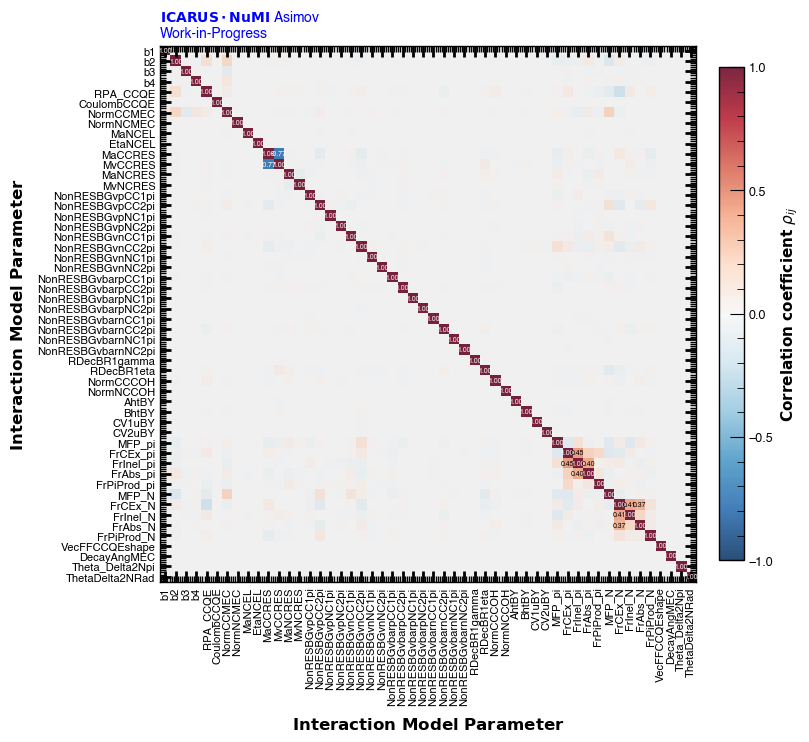

In [26]:
BASE = "FitterEngine/postFit/Hesse/errors"
(fig_cov, ax_cov), (fig_corr, ax_corr) = plot_both_matrices(
    ASIMOV_FILE,
    figsize=(8, 20),
    label_name=r"$\mathbf{Interaction\ Model\ Parameter}$",
    cov_path  = f"{BASE}/Cross section Systematics;1/matrices/Covariance_TH2D;1",
    corr_path = f"{BASE}/Cross section Systematics;1/matrices/Correlation_TH2D;1",
    title_line1=r'$\bf{ICARUS \cdot NuMI}$ Asimov' + '\n' + 'Work-in-Progress',
    annotate=True,
)
save_fig(fig_cov, r'../Plots/dalphaT/Asimov_Containment_2D/Postfits', 'xsec_param_covariance')
save_fig(fig_corr, r'../Plots/dalphaT/Asimov_Containment_2D/Postfits', 'xsec_param_correlation')

Full matrix size: 27×27


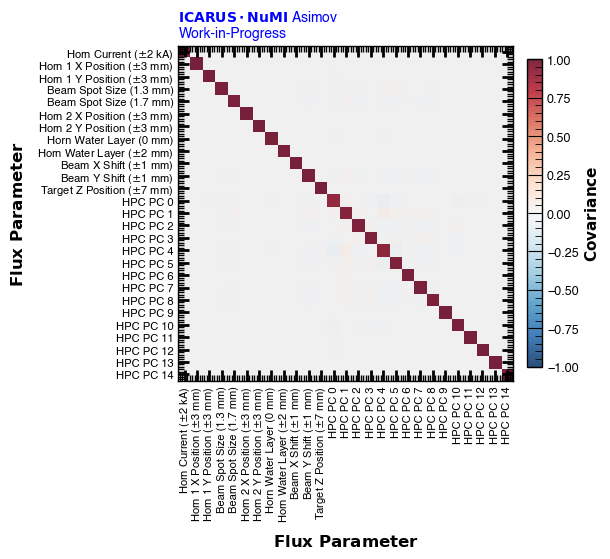

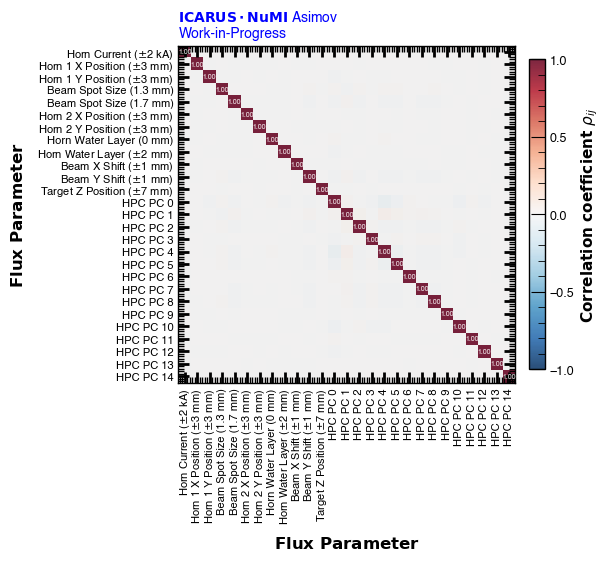

In [27]:
BASE = "FitterEngine/postFit/Hesse/errors"
(fig_cov, ax_cov), (fig_corr, ax_corr) = plot_both_matrices(
    ASIMOV_FILE,
    figsize=(6, 15),
    label_name=r"$\mathbf{Flux\ Parameter}$",
    cov_path  = f"{BASE}/Multisigma Flux Systematics;1/matrices/Covariance_TH2D;1",
    corr_path = f"{BASE}/Multisigma Flux Systematics;1/matrices/Correlation_TH2D;1",
    title_line1=r'$\bf{ICARUS \cdot NuMI}$ Asimov' + '\n' + 'Work-in-Progress',
    annotate=True,
)
save_fig(fig_cov, r'../Plots/dalphaT/Asimov_Containment_2D/Postfits', 'flux_param_covariance')
save_fig(fig_corr, r'../Plots/dalphaT/Asimov_Containment_2D/Postfits', 'flux_param_correlation')

Full matrix size: 9×9


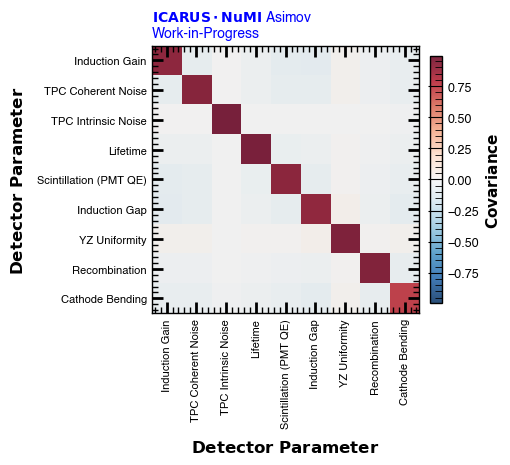

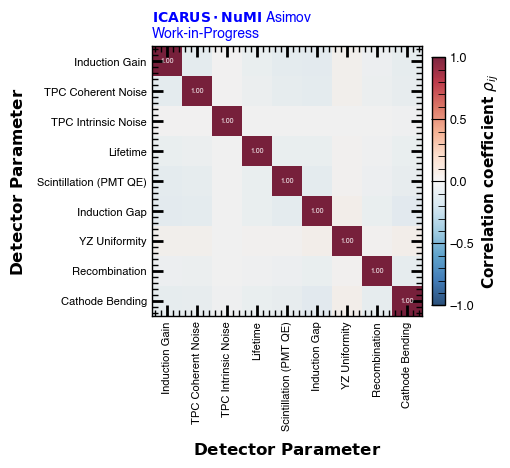

In [28]:
BASE = "FitterEngine/postFit/Hesse/errors"
(fig_cov, ax_cov), (fig_corr, ax_corr) = plot_both_matrices(
    ASIMOV_FILE,
    figsize=(5, 15),
    label_name=r"$\mathbf{Detector\ Parameter}$",
    cov_path  = f"{BASE}/Detector Systematics;1/matrices/Covariance_TH2D;1",
    corr_path = f"{BASE}/Detector Systematics;1/matrices/Correlation_TH2D;1",
    title_line1=r'$\bf{ICARUS \cdot NuMI}$ Asimov' + '\n' + 'Work-in-Progress',
    annotate=True,
)
save_fig(fig_cov, r'../Plots/dalphaT/Asimov_Containment_2D/Postfits', 'detector_param_covariance')
save_fig(fig_corr, r'../Plots/dalphaT/Asimov_Containment_2D/Postfits', 'detector_param_correlation')

Full matrix size: 14×14


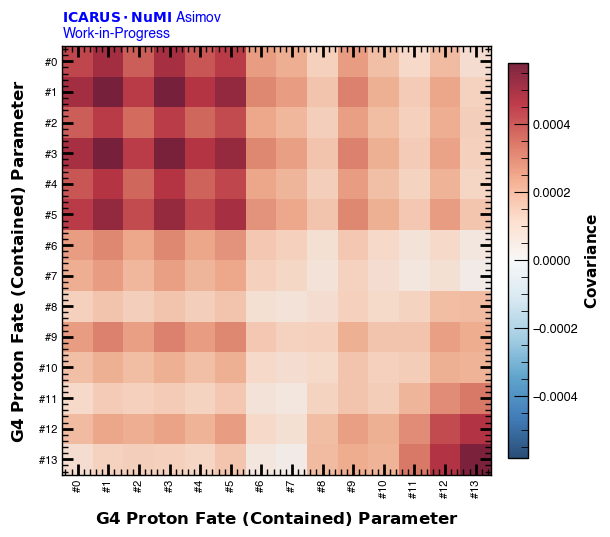

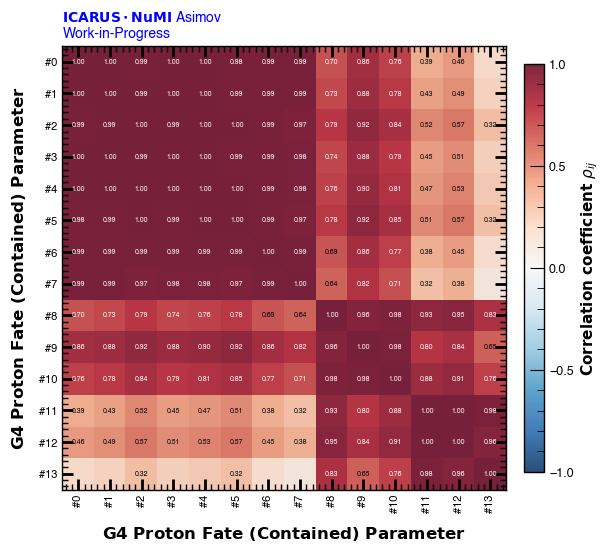

In [29]:
BASE = "FitterEngine/postFit/Hesse/errors"
(fig_cov, ax_cov), (fig_corr, ax_corr) = plot_both_matrices(
    ASIMOV_FILE,
    figsize=(6, 11),
    label_name=r"$\mathbf{G4\ Proton\ Fate\ (Contained)\ Parameter}$",
    cov_path  = f"{BASE}/G4 Proton Fate (dalphaT, contained);1/matrices/Covariance_TH2D;1",
    corr_path = f"{BASE}/G4 Proton Fate (dalphaT, contained);1/matrices/Correlation_TH2D;1",
    title_line1=r'$\bf{ICARUS \cdot NuMI}$ Asimov' + '\n' + 'Work-in-Progress',
    annotate=True,
)
save_fig(fig_cov, r'../Plots/dalphaT/Asimov_Containment_2D/Postfits', 'g4_proton_contained_param_covariance')
save_fig(fig_corr, r'../Plots/dalphaT/Asimov_Containment_2D/Postfits', 'g4_proton_contained_param_correlation')

Full matrix size: 10×10


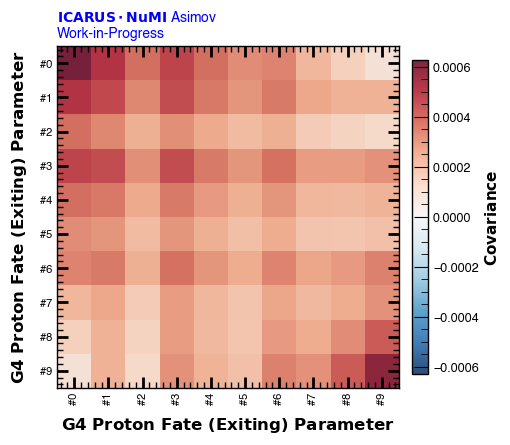

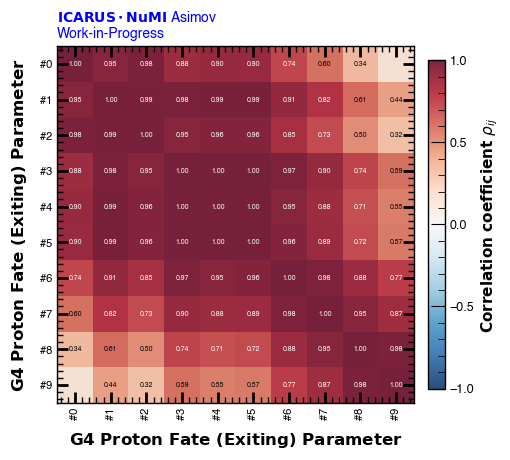

In [30]:
BASE = "FitterEngine/postFit/Hesse/errors"
(fig_cov, ax_cov), (fig_corr, ax_corr) = plot_both_matrices(
    ASIMOV_FILE,
    figsize=(5, 9),
    label_name=r"$\mathbf{G4\ Proton\ Fate\ (Exiting)\ Parameter}$",
    cov_path  = f"{BASE}/G4 Proton Fate (dalphaT, exiting);1/matrices/Covariance_TH2D;1",
    corr_path = f"{BASE}/G4 Proton Fate (dalphaT, exiting);1/matrices/Correlation_TH2D;1",
    title_line1=r'$\bf{ICARUS \cdot NuMI}$ Asimov' + '\n' + 'Work-in-Progress',
    annotate=True,
)
save_fig(fig_cov, r'../Plots/dalphaT/Asimov_Containment_2D/Postfits', 'g4_proton_exiting_param_covariance')
save_fig(fig_corr, r'../Plots/dalphaT/Asimov_Containment_2D/Postfits', 'g4_proton_exiting_param_correlation')

Full matrix size: 14×14


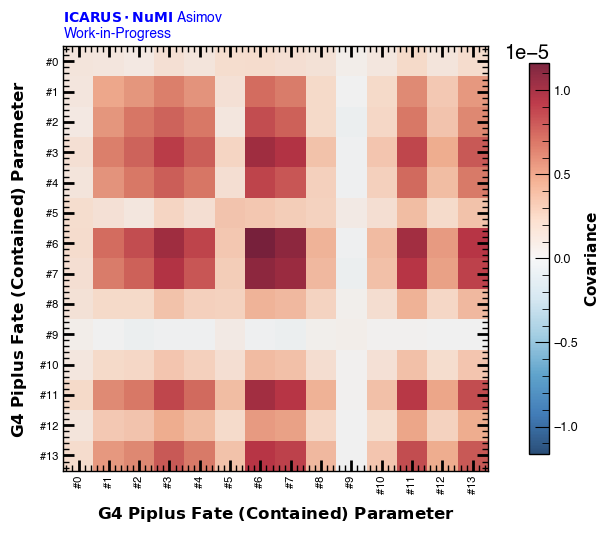

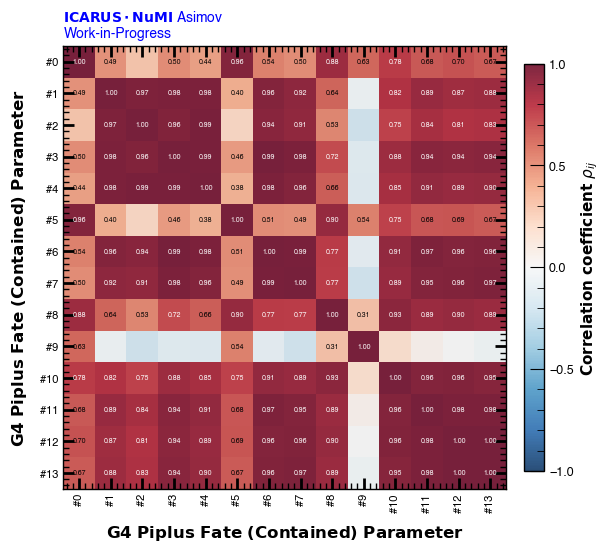

In [31]:
BASE = "FitterEngine/postFit/Hesse/errors"
(fig_cov, ax_cov), (fig_corr, ax_corr) = plot_both_matrices(
    ASIMOV_FILE,
    figsize=(6, 11),
    label_name=r"$\mathbf{G4\ Piplus\ Fate\ (Contained)\ Parameter}$",
    cov_path  = f"{BASE}/G4 Piplus Fate (dalphaT, contained);1/matrices/Covariance_TH2D;1",
    corr_path = f"{BASE}/G4 Piplus Fate (dalphaT, contained);1/matrices/Correlation_TH2D;1",
    title_line1=r'$\bf{ICARUS \cdot NuMI}$ Asimov' + '\n' + 'Work-in-Progress',
    annotate=True,
)
save_fig(fig_cov, r'../Plots/dalphaT/Asimov_Containment_2D/Postfits', 'g4_piplus_contained_param_covariance')
save_fig(fig_corr, r'../Plots/dalphaT/Asimov_Containment_2D/Postfits', 'g4_piplus_contained_param_correlation')

Full matrix size: 10×10


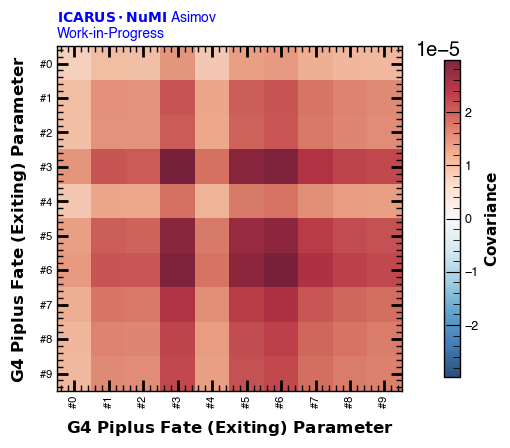

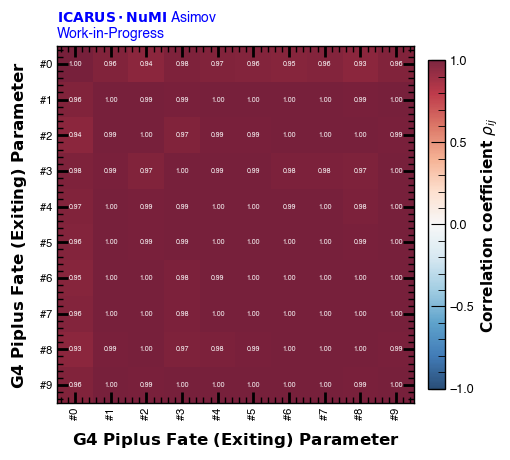

In [32]:
BASE = "FitterEngine/postFit/Hesse/errors"
(fig_cov, ax_cov), (fig_corr, ax_corr) = plot_both_matrices(
    ASIMOV_FILE,
    figsize=(5, 9),
    label_name=r"$\mathbf{G4\ Piplus\ Fate\ (Exiting)\ Parameter}$",
    cov_path  = f"{BASE}/G4 Piplus Fate (dalphaT, exiting);1/matrices/Covariance_TH2D;1",
    corr_path = f"{BASE}/G4 Piplus Fate (dalphaT, exiting);1/matrices/Correlation_TH2D;1",
    title_line1=r'$\bf{ICARUS \cdot NuMI}$ Asimov' + '\n' + 'Work-in-Progress',
    annotate=True,
)
save_fig(fig_cov, r'../Plots/dalphaT/Asimov_Containment_2D/Postfits', 'g4_piplus_exiting_param_covariance')
save_fig(fig_corr, r'../Plots/dalphaT/Asimov_Containment_2D/Postfits', 'g4_piplus_exiting_param_correlation')

Full matrix size: 14×14


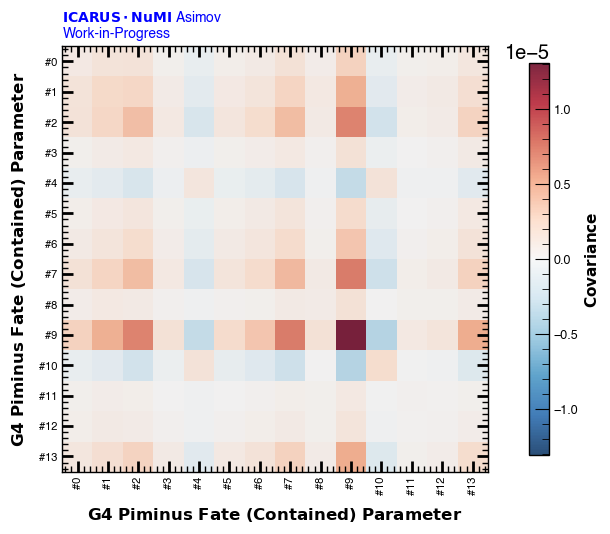

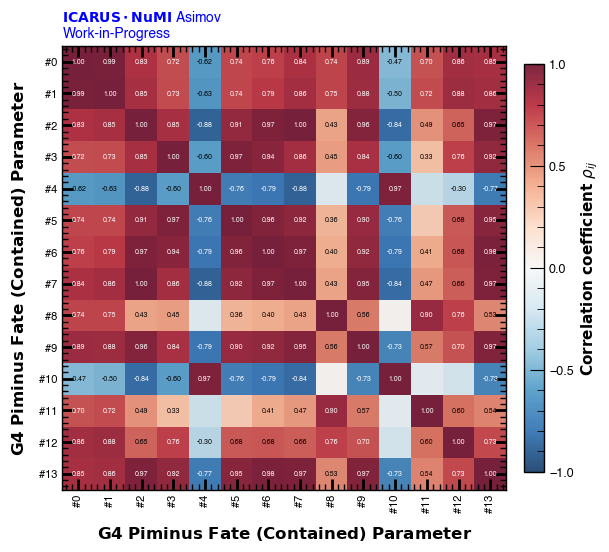

In [33]:
BASE = "FitterEngine/postFit/Hesse/errors"
(fig_cov, ax_cov), (fig_corr, ax_corr) = plot_both_matrices(
    ASIMOV_FILE,
    figsize=(6, 11),
    label_name=r"$\mathbf{G4\ Piminus\ Fate\ (Contained)\ Parameter}$",
    cov_path  = f"{BASE}/G4 Piminus Fate (dalphaT, contained);1/matrices/Covariance_TH2D;1",
    corr_path = f"{BASE}/G4 Piminus Fate (dalphaT, contained);1/matrices/Correlation_TH2D;1",
    title_line1=r'$\bf{ICARUS \cdot NuMI}$ Asimov' + '\n' + 'Work-in-Progress',
    annotate=True,
)
save_fig(fig_cov, r'../Plots/dalphaT/Asimov_Containment_2D/Postfits', 'g4_piminus_contained_param_covariance')
save_fig(fig_corr, r'../Plots/dalphaT/Asimov_Containment_2D/Postfits', 'g4_piminus_contained_param_correlation')

Full matrix size: 10×10


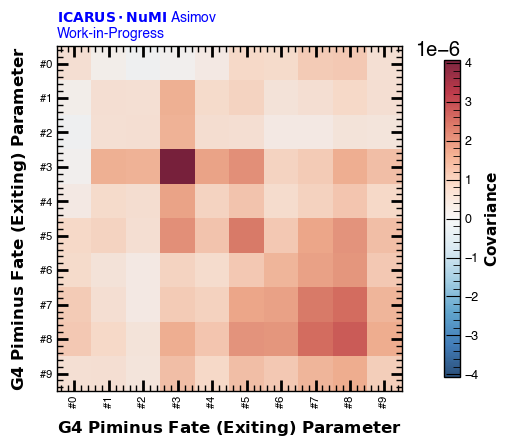

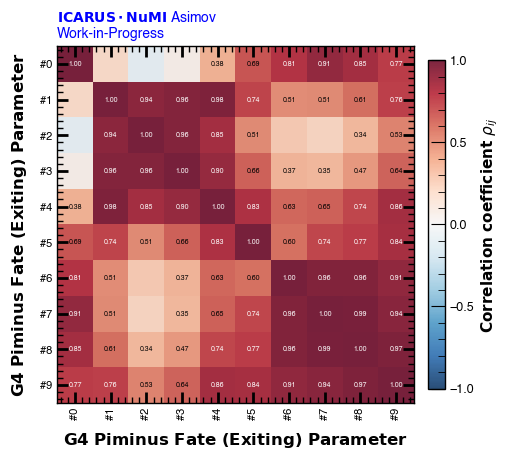

In [34]:
BASE = "FitterEngine/postFit/Hesse/errors"
(fig_cov, ax_cov), (fig_corr, ax_corr) = plot_both_matrices(
    ASIMOV_FILE,
    figsize=(5, 9),
    label_name=r"$\mathbf{G4\ Piminus\ Fate\ (Exiting)\ Parameter}$",
    cov_path  = f"{BASE}/G4 Piminus Fate (dalphaT, exiting);1/matrices/Covariance_TH2D;1",
    corr_path = f"{BASE}/G4 Piminus Fate (dalphaT, exiting);1/matrices/Correlation_TH2D;1",
    title_line1=r'$\bf{ICARUS \cdot NuMI}$ Asimov' + '\n' + 'Work-in-Progress',
    annotate=True,
)
save_fig(fig_cov, r'../Plots/dalphaT/Asimov_Containment_2D/Postfits', 'g4_piminus_exiting_param_covariance')
save_fig(fig_corr, r'../Plots/dalphaT/Asimov_Containment_2D/Postfits', 'g4_piminus_exiting_param_correlation')

## Full Covariance / Correlation Matrix (All Systematics + Template Parameters)

Single matrix over every free parameter in the fit -- template, background-fit, cross-section, flux, detector, and all six G4 groups -- read from the fitter's own postfit Hessian block (`FitterEngine/postFit/Hesse/hessian`), not the per-group `errors` blocks the cells above use. `annotate` is left off here since the matrix is too large for per-cell values to be legible.

Full matrix size: 150×150


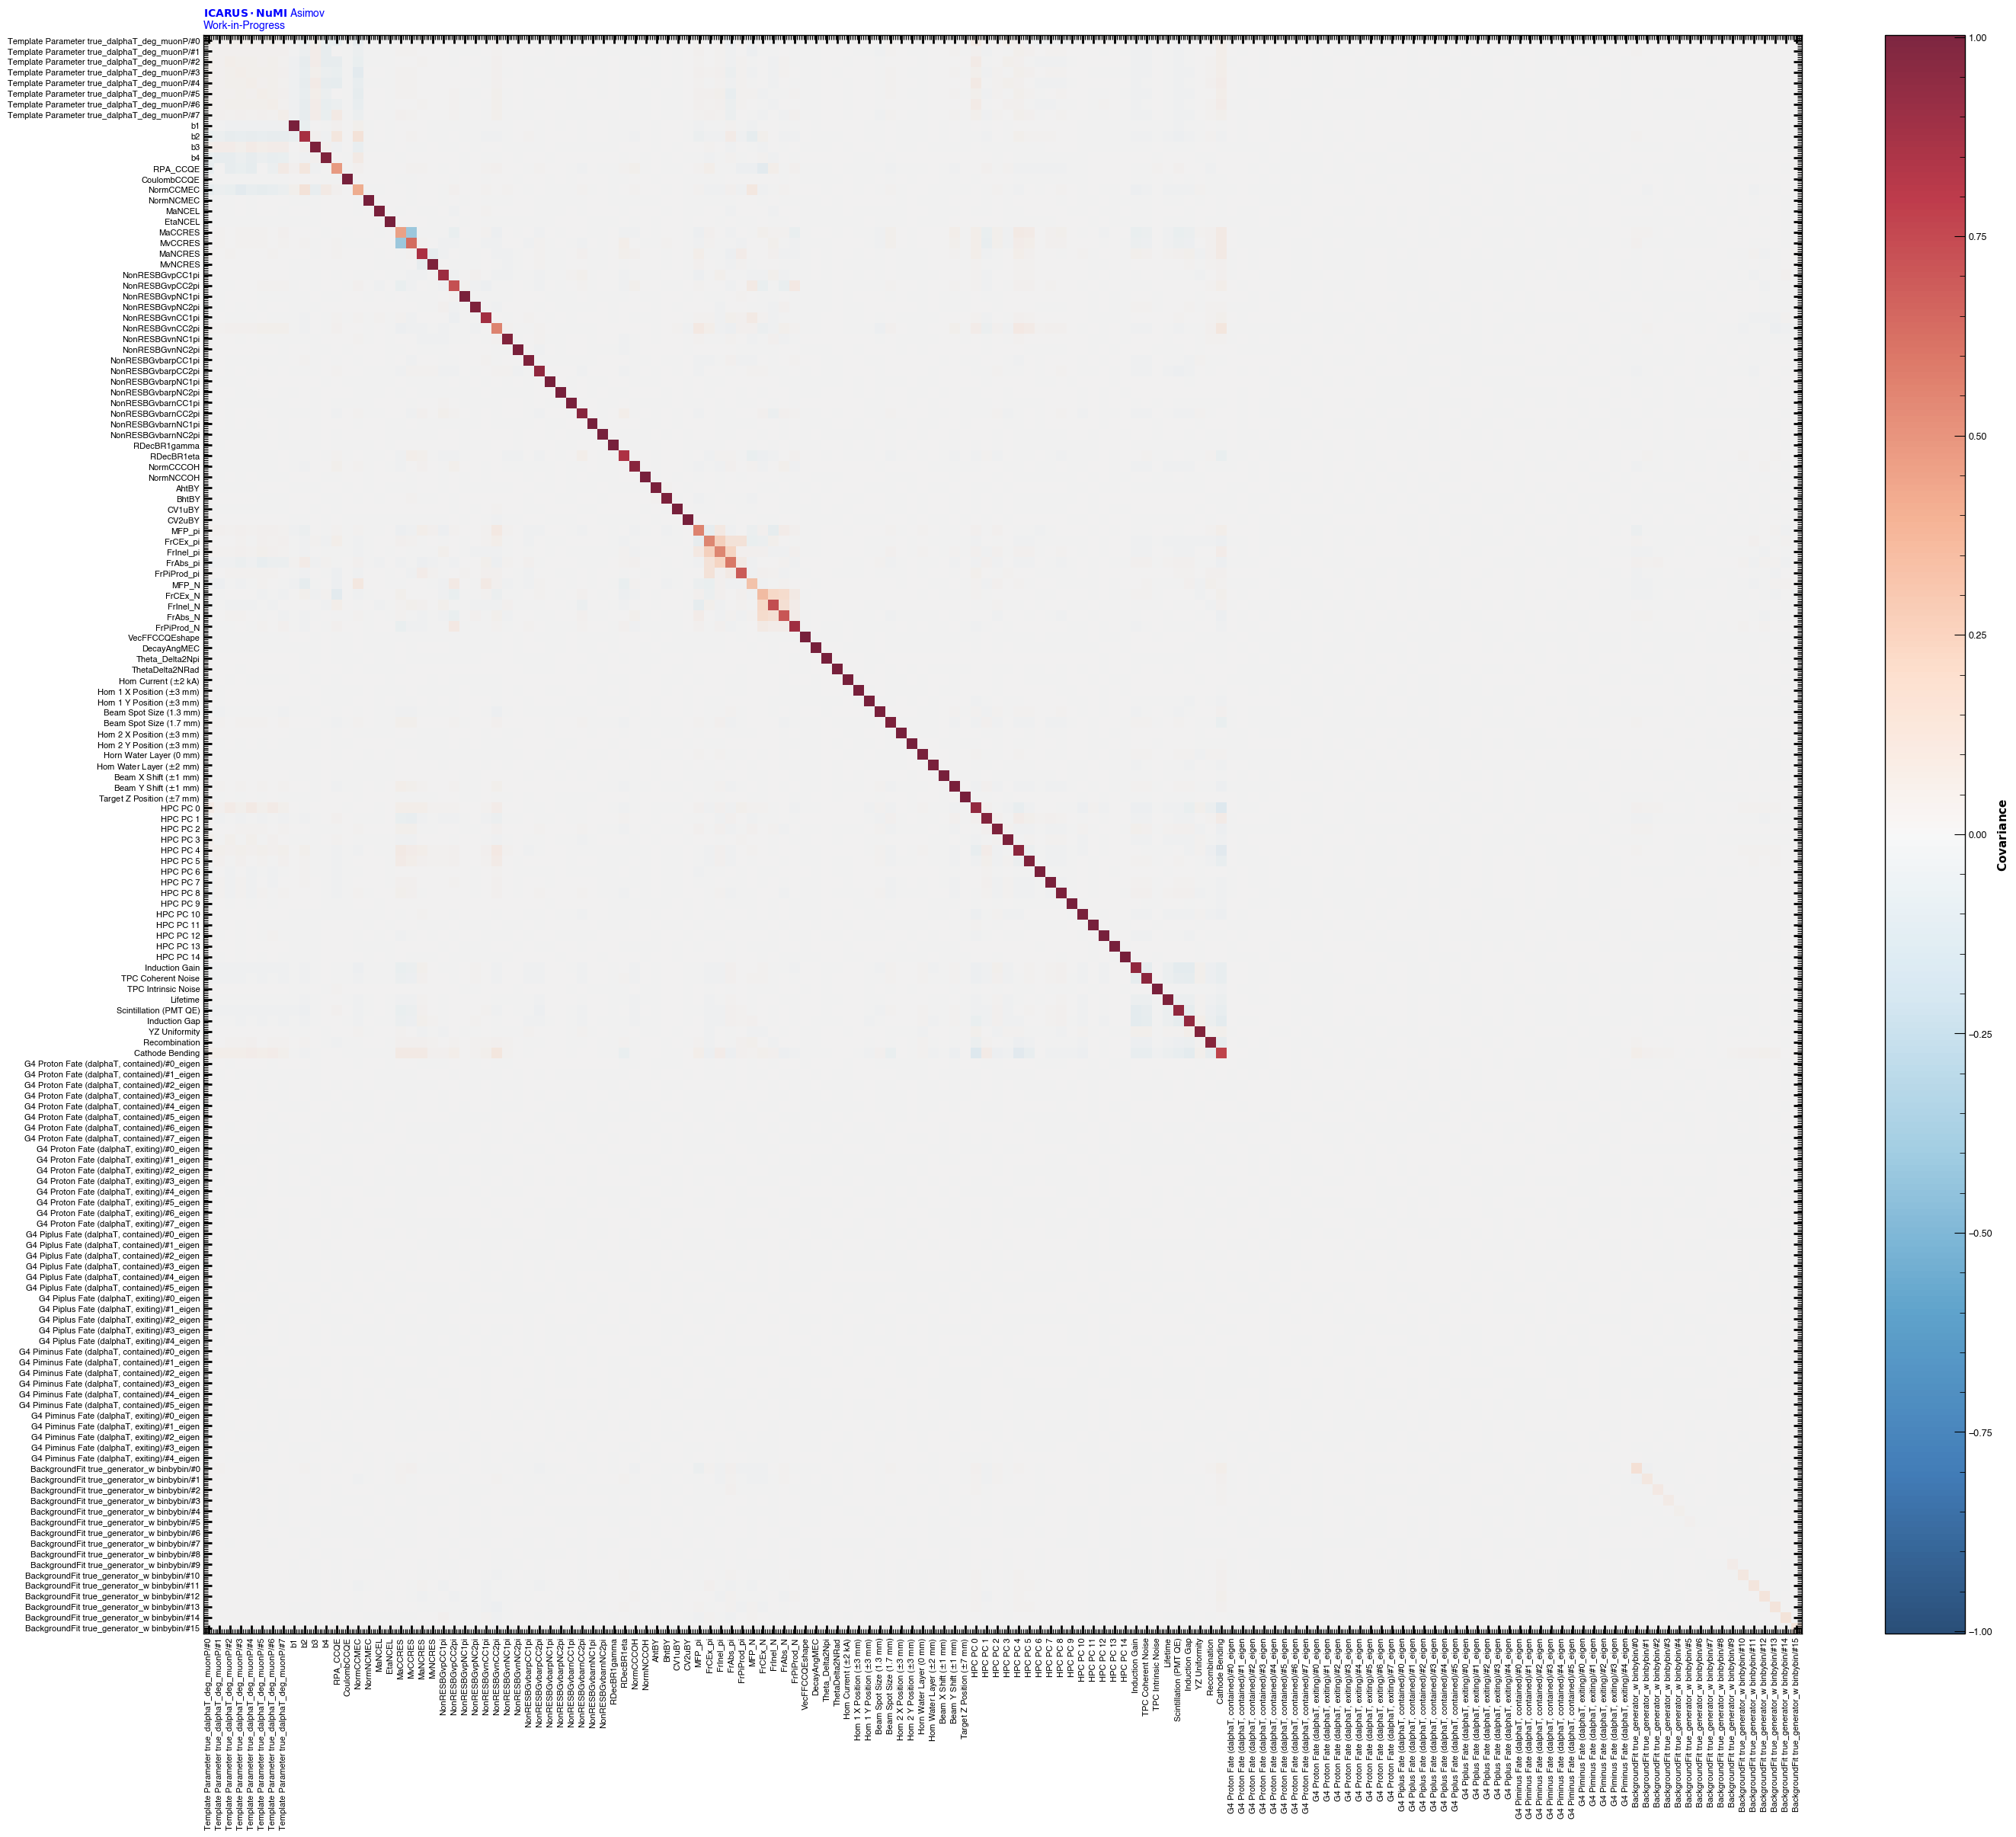

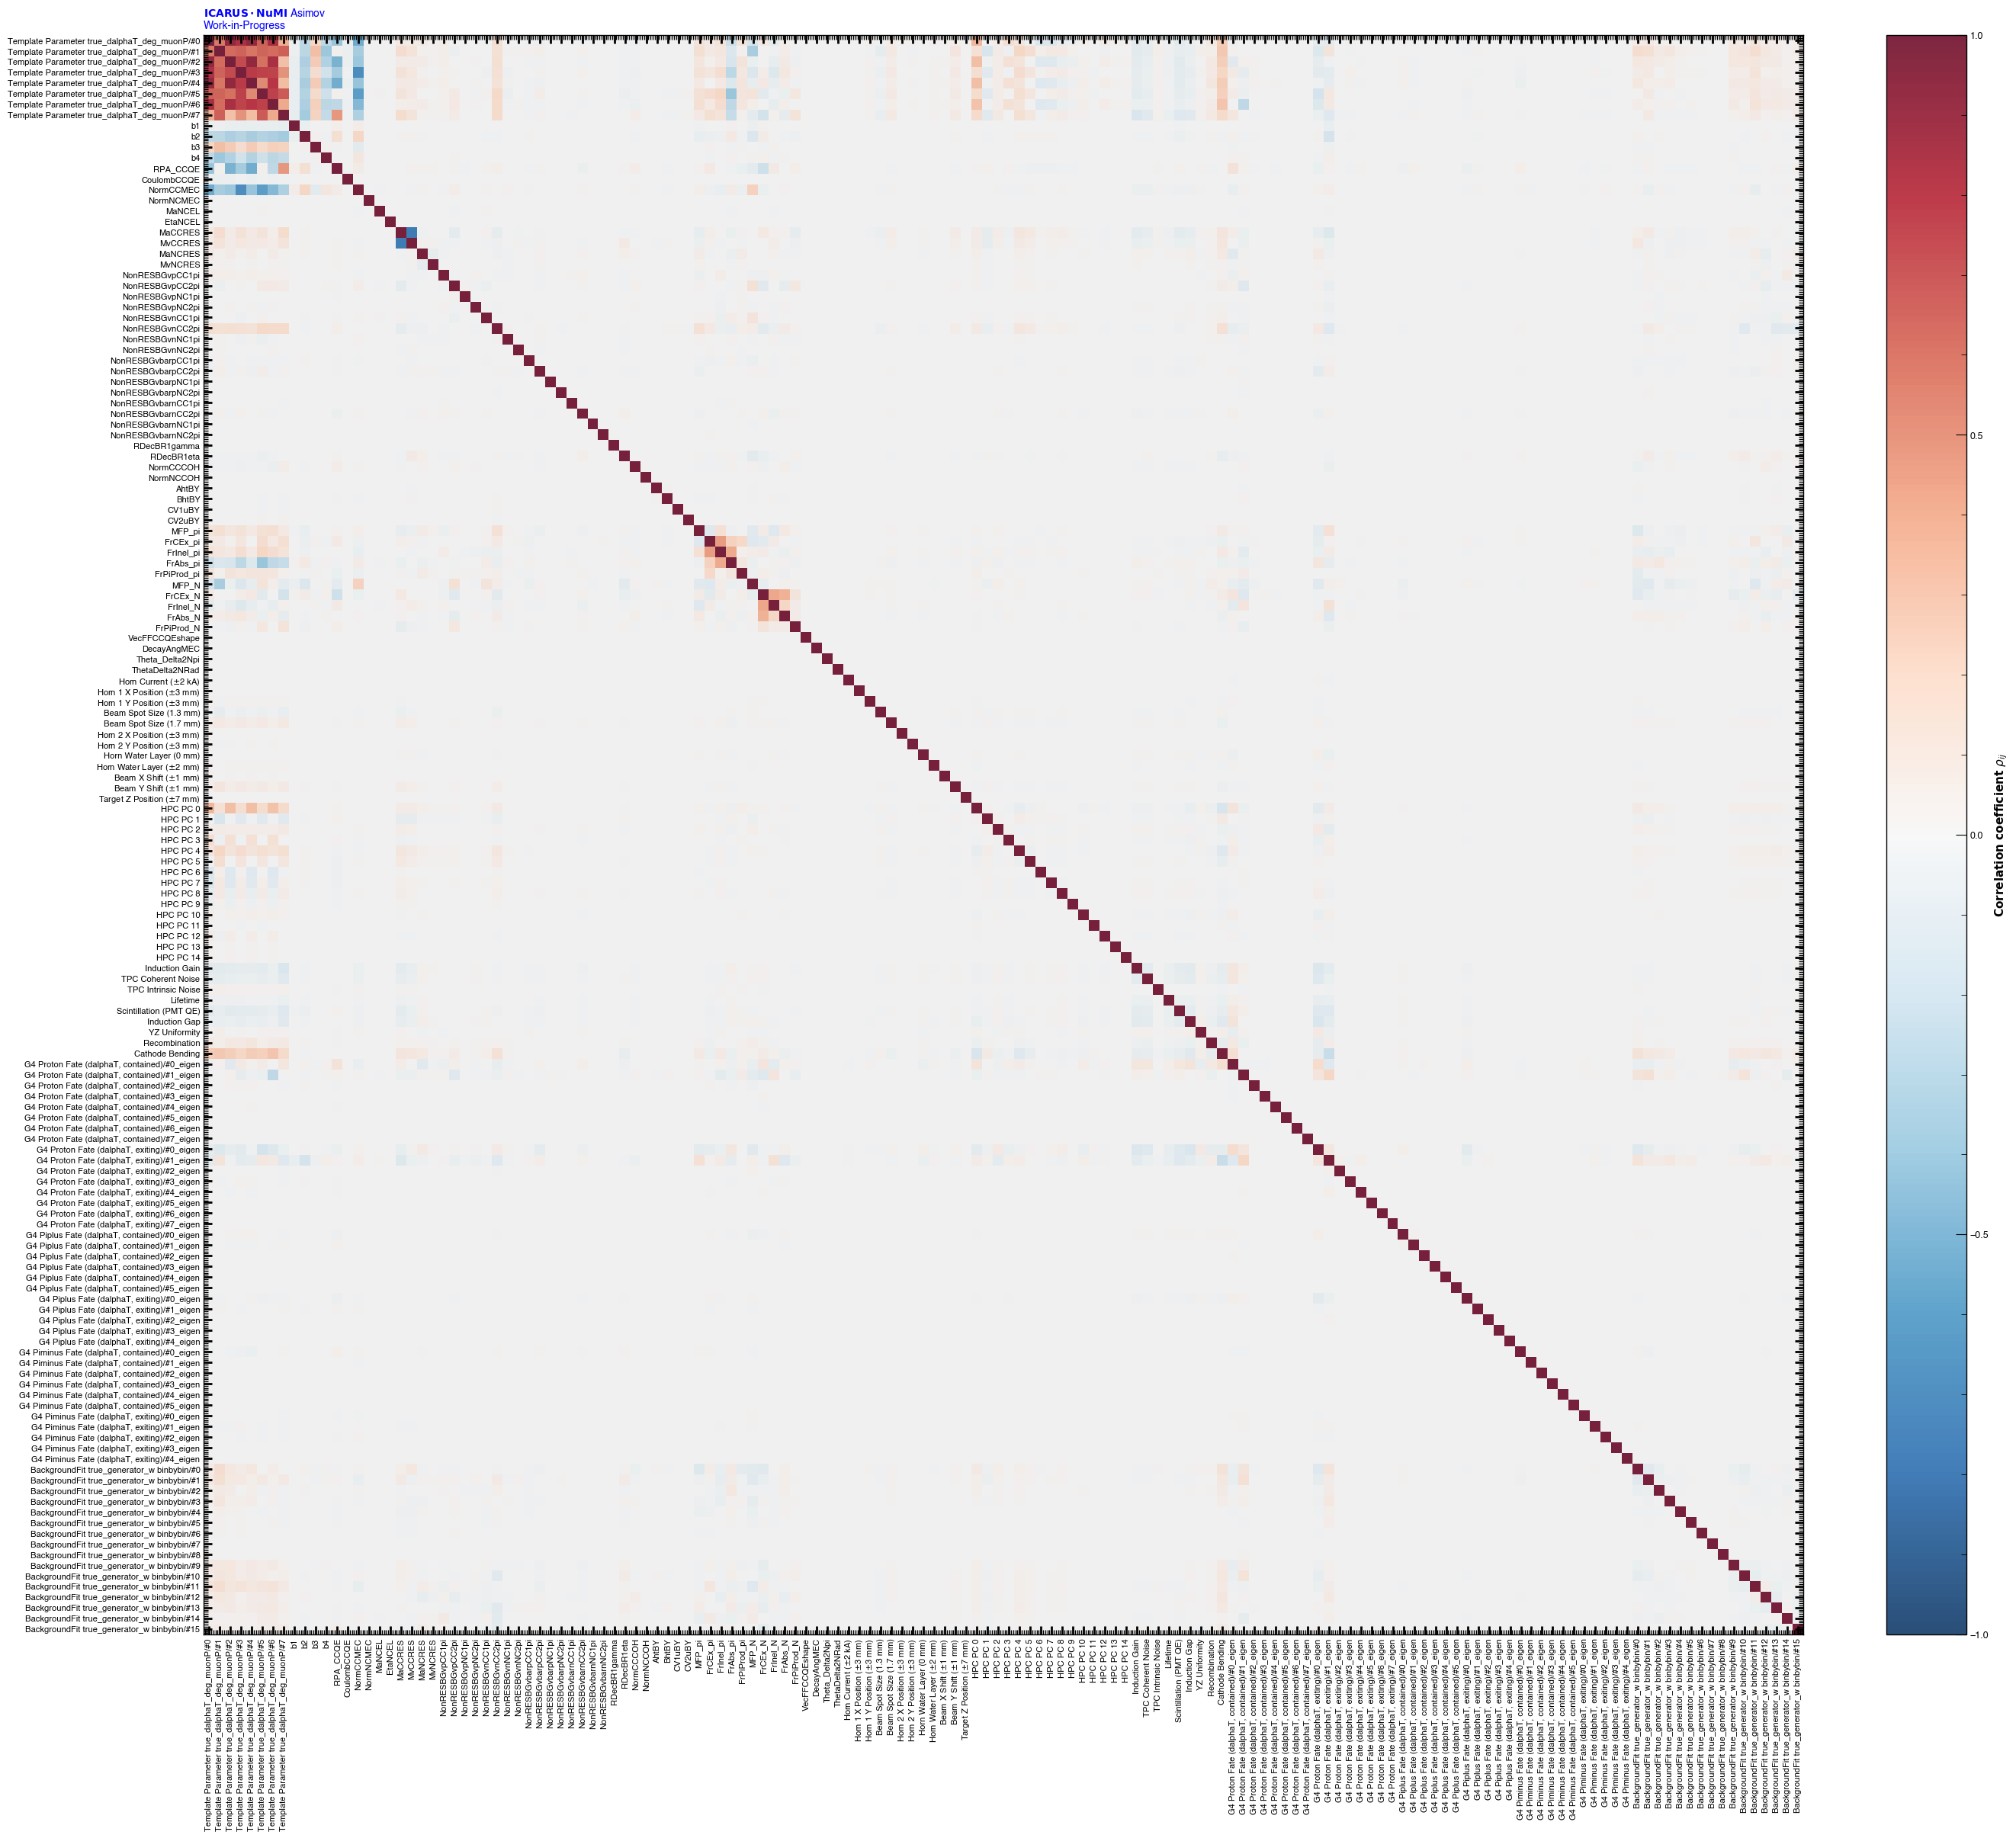

In [35]:
BASE_ALL = "FitterEngine/postFit/Hesse/hessian"
GROUP_ORDER = [
    "Template Parameter true_dalphaT_deg_muonP",
    "Cross section Systematics",
    "Multisigma Flux Systematics",
    "Detector Systematics",
    "G4 Proton Fate (dalphaT, contained)",
    "G4 Proton Fate (dalphaT, exiting)",
    "G4 Piplus Fate (dalphaT, contained)",
    "G4 Piplus Fate (dalphaT, exiting)",
    "G4 Piminus Fate (dalphaT, contained)",
    "G4 Piminus Fate (dalphaT, exiting)",
    "BackgroundFit true_generator_w binbybin",
]
(fig_cov, ax_cov), (fig_corr, ax_corr) = plot_both_matrices(
    ASIMOV_FILE,
    figsize=(30, 24),
    cov_path  = f"{BASE_ALL}/postfitCovariance_TH2D;1",
    corr_path = f"{BASE_ALL}/postfitCorrelation_TH2D;1",
    title_line1=r'$\bf{ICARUS \cdot NuMI}$ Asimov' + '\n' + 'Work-in-Progress',
    annotate=False,
    group_order=GROUP_ORDER,
)
save_fig(fig_cov, r'../Plots/dalphaT/Asimov_Containment_2D/Postfits', 'all_param_covariance')
save_fig(fig_corr, r'../Plots/dalphaT/Asimov_Containment_2D/Postfits', 'all_param_correlation')